# 01. Planteamiento del problema

## Contexto

El Billboard Hot 100 es una de las principales referencias históricas para observar la evolución de la música popular en Estados Unidos. Desde 1958, las canciones que han alcanzado la primera posición reflejan cambios en las preferencias del público, las tendencias de producción musical y la diversidad de estilos que han conseguido mayor difusión comercial.

Sin embargo, alcanzar el primer lugar no significa necesariamente que las canciones compartan las mismas características sonoras, ni que la música popular haya evolucionado de manera uniforme.

Este análisis busca explorar cómo ha cambiado el sonido de las canciones que alcanzaron el número uno del Billboard Hot 100 entre 1958 y 2025, considerando tanto las transformaciones de sus características musicales como la diversidad y las relaciones entre los géneros presentes en cada época.

## Pregunta de investigación

**¿Cómo ha evolucionado el sonido de las canciones que alcanzaron el número uno del Billboard Hot 100: ha cambiado su perfil sonoro y se ha vuelto más homogéneo con el paso del tiempo?**

## Objetivo general

Analizar la evolución de las características sonoras y la diversidad musical de las canciones que alcanzaron el número uno del Billboard Hot 100 entre 1958 y 2025, identificando patrones temporales, diferencias entre épocas y relaciones entre géneros musicales.

## Objetivos específicos

1. Identificar cambios en las características sonoras de las canciones a través del tiempo.
2. Examinar si la diversidad sonora dentro de cada época ha aumentado, disminuido o permanecido relativamente estable.
3. Explorar las relaciones y patrones de coexistencia entre géneros y estilos musicales a lo largo de las décadas.
4. Evaluar los resultados mediante métodos estadísticos apropiados para las características y distribuciones observadas.
5. Comunicar los hallazgos mediante visualizaciones que faciliten su interpretación.

## Dimensiones de análisis

### A. Evolución del perfil sonoro

Examinar cómo han cambiado características como el tempo, la energía, la bailabilidad, la felicidad percibida, la intensidad sonora y la acústica.

### B. Diversidad sonora

Evaluar qué tan diferentes son las canciones dentro de cada época, utilizando una medida de dispersión multivariada respecto al perfil sonoro promedio de su periodo.

### C. Relaciones entre géneros musicales

Representar los géneros y estilos como redes de coocurrencia, donde las conexiones reflejan su presencia conjunta en las canciones. Esto permitirá explorar cómo cambian las asociaciones entre categorías musicales a través del tiempo.

## Hipótesis de investigación

La hipótesis estadística principal se definirá después de examinar las distribuciones, la cobertura de los datos y los patrones exploratorios.

Una posibilidad que se evaluará es que la diversidad sonora de las canciones que alcanzaron el número uno haya cambiado entre las distintas épocas, incluyendo la posibilidad de una reducción de la dispersión en periodos más recientes.

No se asumirá de antemano que existe una tendencia lineal ni que la música se ha vuelto progresivamente homogénea.

## Alcance y consideraciones

- El análisis se limita a las canciones incluidas en el conjunto de datos que alcanzaron el número uno; no representa toda la música producida o publicada durante cada época.
- Las características sonoras disponibles pueden provenir de mediciones automatizadas y no necesariamente capturan todos los elementos musicales.
- Las clasificaciones de género y estilo dependen de las fuentes y criterios de etiquetado disponibles.
- Las diferencias observadas representan asociaciones y patrones temporales, no relaciones causales.
- Las comparaciones entre épocas considerarán la disponibilidad y calidad de los datos para evitar conclusiones basadas en muestras incompletas.

## Enfoque metodológico

El trabajo combinará análisis exploratorio, estadística descriptiva, visualización, análisis de dispersión multivariada y análisis de redes.

La selección de pruebas estadísticas dependerá de las características de los datos, sus distribuciones, la estructura de las observaciones y los supuestos de cada método. Se priorizará la interpretación y la robustez de los resultados sobre la complejidad matemática.

In [2]:
## Celda 1 — Importaciones y configuración

from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns

# Configuración general y visual
RANDOM_STATE = 42
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (12, 6)

RAW_DATA_PATH = Path("../data/raw/Billboard_Hot_100_Number_Ones_Database.xlsx")

AUDIO_FEATURES = ["BPM", "Energy", "Danceability", "Happiness", "Loudness (dB)", "Acousticness"]
GENRE_COLUMNS = ["CDR Genre", "CDR Style", "Discogs Genre", "Discogs Style"]
IDENTIFIER_COLUMNS = ["Song", "Artist", "Date"]

In [3]:
## Celda 2 — Carga y preservación de los datos originales
raw = pd.read_excel( RAW_DATA_PATH, sheet_name="Data", na_values=["Cannot Locate"])

# Copia de trabajo
df = raw.copy(deep=True)

print(f"Registros originales: {len(raw):,}")
print(f"Columnas originales: {raw.shape[1]:,}")

display(df.head())

Registros originales: 1,177
Columnas originales: 105


,Song,Artist,Date,Weeks at Number One,Non-Consecutive,Rating 1,Rating 2,Rating 3,Overall Rating,Divisiveness,...,Featured in a Then Contemporary Play,Written for a Film,Featured in a Then Contemporary Film,Written for a T.V. Show,Featured in a then Contemporary T.V. Show,Associated with Dance,Topped the Charts by Multiple Artist,Double A Side,Eurovision Entry,U.S. Artwork
0,Poor Little Fool,Ricky Nelson,1958-08-04,2,0,4,5,3,4.000000,1.333333,...,NaN,0,NaN,0,NaN,0,0,NaN,0,NaN
1,Nel Blu Dipinto Di Blu,Domenico Modugno,1958-08-18,5,1,7,7,5,6.333333,1.333333,...,NaN,0,NaN,0,NaN,0,0,NaN,1,NaN
2,Little Star,The Elegants,1958-08-25,1,0,5,6,6,5.666667,0.666667,...,NaN,0,NaN,0,NaN,0,0,NaN,0,NaN
3,It's All in the Game,Tommy Edwards,1958-09-29,6,0,3,3,7,4.333333,2.666667,...,NaN,0,NaN,0,NaN,0,0,NaN,0,NaN
4,It's Only Make Believe,Conway Twitty,1958-11-10,2,1,7,8,9,8.000000,1.333333,...,NaN,0,NaN,0,NaN,0,0,NaN,0,NaN


In [4]:
## Celda 3 — Validación estructural inicial 
required_columns = IDENTIFIER_COLUMNS + AUDIO_FEATURES + GENRE_COLUMNS + ["Weeks at Number One"]
missing_columns = [col for col in required_columns if col not in df.columns]

if missing_columns:
    raise ValueError(f"Faltan columnas necesarias: {missing_columns}")

df["Date"] = pd.to_datetime(df["Date"], errors="coerce")
print(f"Dimensiones: {df.shape} | Fechas: {df['Date'].min().date()} a {df['Date'].max().date()} | Nulas: {df['Date'].isna().sum()}")

Dimensiones: (1177, 105) | Fechas: 1958-08-04 a 2025-01-11 | Nulas: 0


In [5]:
## Celda 4 — Identificación de duplicados

duplicate_checks = {
    "Filas completamente duplicadas": df.duplicated().sum(),
    "Canción, artista y fecha duplicados": df.duplicated(subset=["Song", "Artist", "Date"]).sum(),
    "Canción y artista duplicados": df.duplicated(subset=["Song", "Artist"]).sum(),
}

display(pd.Series(duplicate_checks, name="Cantidad").to_frame())

,Cantidad
Filas completamente duplicadas,0
"Canción, artista y fecha duplicados",0
Canción y artista duplicados,0


In [6]:
## Celda 5 — Variables temporales

df["Year"] = df["Date"].dt.year
period_bins = [1958, 1970, 1980, 1990, 2000, 2010, 2020, 2026]
period_labels = ["1958-1969", "1970s", "1980s", "1990s", "2000s", "2010s", "2020-2025"]

df["Epoch"] = pd.Categorical(
    pd.cut(df["Year"], bins=period_bins, labels=period_labels, right=False),
    categories=period_labels,
    ordered=True
)

display(df.groupby("Epoch", observed=False).size().rename("Songs").to_frame())

,Songs
Epoch,
1958-1969,226
1970s,253
1980s,231
1990s,140
2000s,129
2010s,116
2020-2025,82


In [7]:
## Celda 6 — Indicadores de calidad

# Valores ausentes
missing_summary = df.isna().sum().to_frame("Missing")

missing_summary["Missing_Percentage"] = (missing_summary["Missing"] / len(df) * 100).round(2)

display(missing_summary.sort_values("Missing_Percentage", ascending=False).head(20))

,Missing,Missing_Percentage
Featured in a Then Contemporary Play,1175,99.83
Talent Contestant,1166,99.07
Double A Side,1165,98.98
Featured in a then Contemporary T.V. Show,1152,97.88
Sound Effects,1113,94.56
Featured in a Then Contemporary Film,1073,91.16
Featured Artists,988,83.94
U.S. Artwork,424,36.02
Discogs Style,94,7.99
CDR Genre,88,7.48


In [8]:
## Celda 7 — Identificación de BPM sospechosos

df["BPM_flagged"] = df["BPM"].notna() & ((df["BPM"] < 40) | (df["BPM"] > 220))
display(df.loc[df["BPM_flagged"], ["Song", "Artist", "Date", "BPM"]])

,Song,Artist,Date,BPM
546,Against All Odds (Take a Look at Me Now),Phil Collins,1984-04-21,16.0


In [9]:
## Celda 8 — Auditoría de integridad de la muestra

df["Audio_Complete"] = df[AUDIO_FEATURES].notna().all(axis=1)

audio_audit = df.groupby("Epoch", observed=False).agg(Total_Songs=("Song", "size"), Complete_Audio=("Audio_Complete", "sum"))
audio_audit["Incomplete_Audio"] = audio_audit["Total_Songs"] - audio_audit["Complete_Audio"]
audio_audit["Coverage_Percentage"] = (audio_audit["Complete_Audio"] / audio_audit["Total_Songs"] * 100).round(2)

display(audio_audit)

,Total_Songs,Complete_Audio,Incomplete_Audio,Coverage_Percentage
Epoch,,,,
1958-1969,226,226,0,100.00
1970s,253,253,0,100.00
1980s,231,230,1,99.57
1990s,140,139,1,99.29
2000s,129,129,0,100.00
2010s,116,116,0,100.00
2020-2025,82,82,0,100.00


In [10]:
incomplete_audio = df.loc[~df["Audio_Complete"], ["Song", "Artist", "Date", "Epoch", *AUDIO_FEATURES, "BPM_flagged"]]

print(f"Total de registros: {len(df)}")
print(f"Registros con audio completo: {df['Audio_Complete'].sum()}")
print(f"Registros con audio incompleto: {len(incomplete_audio)}")

display(incomplete_audio)

Total de registros: 1177
Registros con audio completo: 1175
Registros con audio incompleto: 2


,Song,Artist,Date,Epoch,BPM,Energy,Danceability,Happiness,Loudness (dB),Acousticness,BPM_flagged
690,Rock On,Michael Damian,1989-06-03,1980s,NaN,NaN,NaN,NaN,NaN,NaN,False
834,Lately,Divine,1998-11-28,1990s,NaN,NaN,NaN,NaN,NaN,NaN,False


In [11]:
 ## Celda 9 — Preparación de la muestra analítica

# Copia exclusiva para análisis
analysis = df.copy(deep=True)

# El BPM sospechoso se excluye de la muestra analítica principal.
# No modificamos df ni raw.
analysis.loc[
    analysis["BPM_flagged"],
    "BPM"
] = np.nan

# Muestra con las seis características disponibles
audio_complete = analysis.dropna(
    subset=AUDIO_FEATURES
).copy()

print("Registros originales:", len(raw))
print("Registros con audio completo:", len(audio_complete))
print(
    "Registros excluidos del análisis multivariado:",
    len(analysis) - len(audio_complete)
)

assert len(raw) == 1177
assert len(audio_complete) == 1174

Registros originales: 1177
Registros con audio completo: 1174
Registros excluidos del análisis multivariado: 3


In [12]:
## Celda 10 — Estadística descriptiva del perfil sonoro

audio_summary = (
    analysis
    .groupby("Epoch", observed=True)[AUDIO_FEATURES]
    .agg(["count", "mean", "median", "std"])
)

display(audio_summary.round(2))

BPM                       Energy                       \
          count    mean median    std  count   mean median    std   
Epoch                                                               
1958-1969   226  115.41  117.0  24.12    226  53.69   54.0  20.54   
1970s       253  115.45  112.0  21.89    253  55.66   55.0  18.71   
1980s       229  116.09  115.0  23.73    230  63.08   64.0  20.65   
1990s       139  111.50  108.0  22.68    139  61.82   61.0  19.06   
2000s       129  115.98  114.0  26.65    129  68.17   68.0  13.92   
2010s       116  118.01  120.0  23.25    116  66.82   70.0  16.95   
2020-2025    82  123.04  118.5  32.70     82  63.40   65.0  13.84   

          Danceability         ... Happiness        Loudness (dB)         \
                 count   mean  ...    median    std         count   mean   
Epoch                          ...                                         
1958-1969          226  54.11  ...      70.0  22.61           226  -9.87   
1970s              253  60.14  ...      75.0  23.78           253 -10.87   
1980s              230  64.00  ...      67.5  27.08           230  -9.34   
1990s              139  65.38  ...      53.0  27.41           139  -8.29   
2000s              129  70.36  ...      65.0  21.81           129  -5.75   
2010s              116  69.69  ...      55.0  21.56           116  -5.65   
2020-2025           82  67.67  ...      54.0  22.06            82  -6.41   

                       Acousticness                       
          median   std        count   mean median    std  
Epoch                                                     
1958-1969  -10.0  3.20          226  51.73   60.0  28.49  
1970s      -11.0  3.14          253  35.97   31.0  27.24  
1980s       -9.0  3.45          230  23.54   17.0  21.99  
1990s       -8.0  2.33          139  24.86   15.0  25.15  
2000s       -6.0  1.98          129  14.53    9.0  15.68  
2010s       -6.0  1.77          116  17.72    8.0  23.43  
2020-2025   -6.0  1.77           82  20.51   12.0  22.82  

[7 rows x 24 columns]

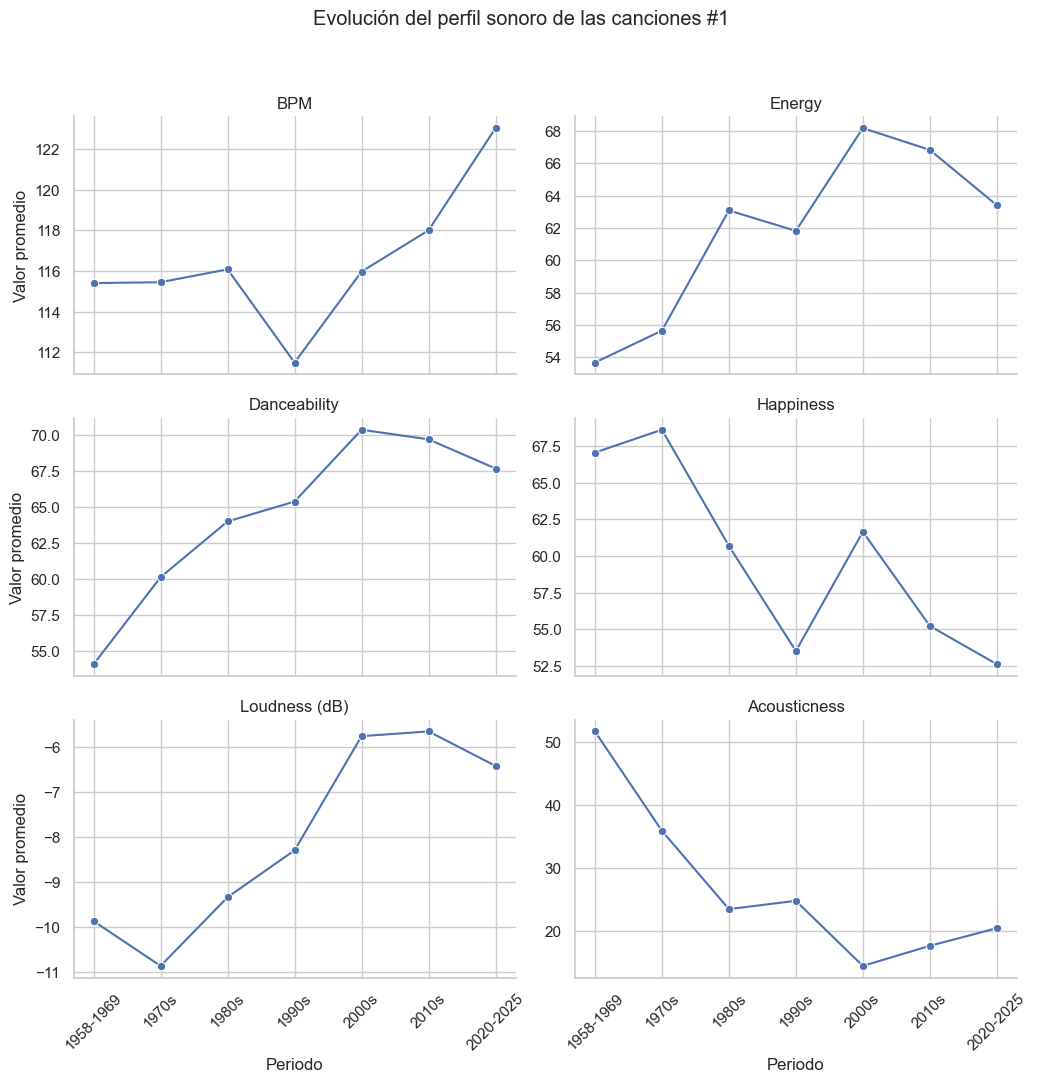

In [13]:
audio_means = analysis.groupby("Epoch", observed=True)[AUDIO_FEATURES].mean().reset_index()
audio_long = audio_means.melt(id_vars="Epoch", var_name="Feature", value_name="Mean_Value")

g = sns.FacetGrid(audio_long, col="Feature", col_wrap=2, sharey=False, height=3.5, aspect=1.5)
g.map_dataframe(sns.lineplot, x="Epoch", y="Mean_Value", marker="o")
g.set_titles("{col_name}")
g.set_axis_labels("Periodo", "Valor promedio")

for ax in g.axes.flat:
    ax.tick_params(axis="x", rotation=45)

g.figure.suptitle("Evolución del perfil sonoro de las canciones #1", y=1.03)
plt.tight_layout()
plt.show()

In [14]:
def calculate_epoch_dispersion(data: pd.DataFrame, features: list[str], epoch_column: str = "Epoch"):
    X = data[features].copy()
    if X.isna().any().any():
        raise ValueError("Existen valores ausentes en las características.")
    
    means, stds = X.mean(), X.std()
    if (stds == 0).any():
        raise ValueError("No se puede estandarizar una característica constante.")
    
    Z = (X - means) / stds
    row_centroids = Z.groupby(data[epoch_column], observed=True).transform("mean")
    distances = np.sqrt(((Z - row_centroids) ** 2).sum(axis=1))
    
    result = data.copy()
    result["Distance_To_Centroid"] = distances
    scaler = pd.DataFrame({"Mean": means, "Standard_Deviation": stds})
    
    return result, Z.groupby(data[epoch_column], observed=True).mean(), scaler

dispersion_data, epoch_centroids, audio_scaler = calculate_epoch_dispersion(audio_complete, AUDIO_FEATURES)

dispersion_summary = dispersion_data.groupby("Epoch", observed=True)["Distance_To_Centroid"].agg(
    Count="count", Mean="mean", Median="median", Std="std"
)

display(dispersion_summary.round(3))

,Count,Mean,Median,Std
Epoch,,,,
1958-1969,226,2.281,2.134,0.781
1970s,253,2.216,2.127,0.773
1980s,229,2.276,2.169,0.771
1990s,139,2.196,2.108,0.620
2000s,129,1.887,1.818,0.627
2010s,116,1.868,1.801,0.712
2020-2025,82,2.085,2.012,0.660


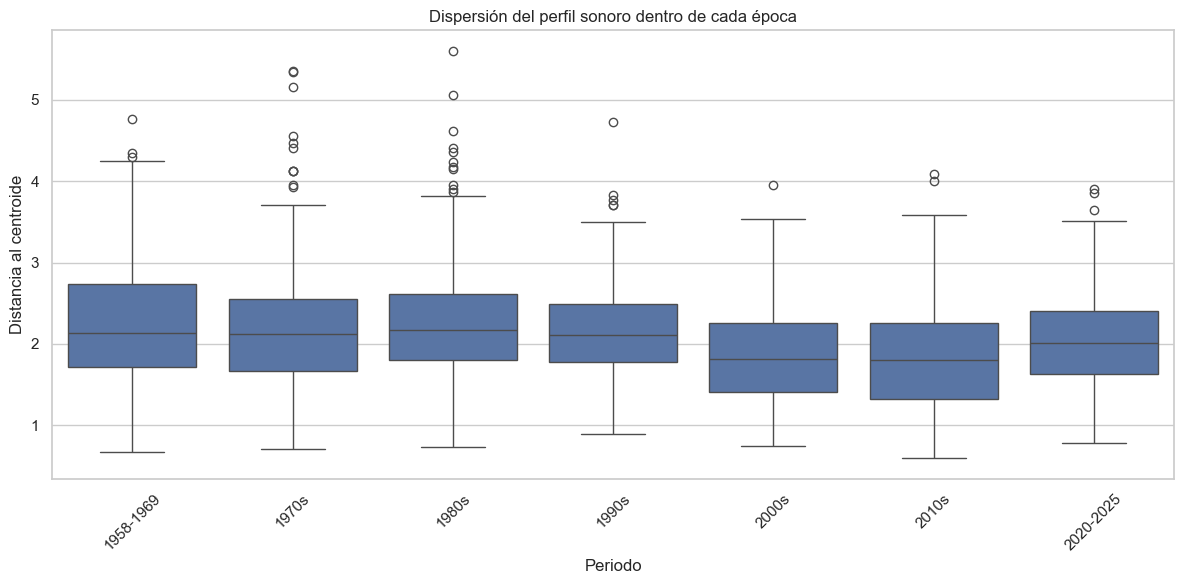

In [15]:
plt.figure(figsize=(12, 6))

sns.boxplot(
    data=dispersion_data,
    x="Epoch",
    y="Distance_To_Centroid",
)

plt.title(
    "Dispersión del perfil sonoro dentro de cada época"
)

plt.xlabel("Periodo")
plt.ylabel("Distancia al centroide")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## Celda 13 — Inspección de géneros y estilos musicales

## Antes de construirlas, necesitamos entender cómo están almacenadas las etiquetas.
##  No vamos a mezclar indiscriminadamente CDR Genre, CDR Style, Discogs Genre y Discogs Style: son fuentes y niveles de clasificación diferentes.

## Queremos descubrir cosas como:
- Si una canción puede tener varios géneros.
- Si las etiquetas están separadas por comas, punto y coma u otro delimitador.
- Si existen diferencias entre la clasificación de CDR y Discogs.
- Cuántas categorías diferentes tenemos.
- Si hay etiquetas redundantes o inconsistentes.
Con eso podremos diseñar una red en la que:
- Nodo: género o estilo musical.
- Tamaño: frecuencia de aparición en las canciones.
- Conexión: dos géneros aparecen juntos en una misma canción.
- Peso de conexión: cantidad de canciones que comparten esa combinación.
- Periodo: permite comparar cómo cambian las relaciones a través del tiempo.

In [18]:


for column in GENRE_COLUMNS:

    print(f"\n{'=' * 60}")
    print(f"VARIABLE: {column}")
    print(f"{'=' * 60}")

    print("Valores no nulos:", df[column].notna().sum())
    print("Valores únicos:", df[column].nunique())

    print("\nEtiquetas más frecuentes:")

    display(
        df[column]
        .dropna()
        .value_counts()
        .head(20)
        .to_frame("Frequency")
    )

    print("\nEjemplos originales:")

    display(
        df[column]
        .dropna()
        .sample(
            min(5, df[column].notna().sum()),
            random_state=RANDOM_STATE,
        )
    )


VARIABLE: CDR Genre
Valores no nulos: 1089
Valores únicos: 32

Etiquetas más frecuentes:


,Frequency
CDR Genre,
Pop,342
Rock,271
Funk/Soul,217
Hip Hop,87
Electronic/Dance,87
Folk/Country,23
Reggae,10
Rock;Funk/Soul,7
Funk/Soul;Rock,6



Ejemplos originales:


355             Rock
56      Folk/Country
478             Rock
566              Pop
1066         Hip Hop
Name: CDR Genre, dtype: object


VARIABLE: CDR Style
Valores no nulos: 1089
Valores únicos: 181

Etiquetas más frecuentes:


,Frequency
CDR Style,
Vocal,119
Pop Rock,103
R&B,76
Vocal;Ballad,65
Rock & Roll,54
Hip Hop,48
Soul,40
Disco,40
Motown,33


... (6 outputs left out)


VARIABLE: Discogs Style
Valores no nulos: 1083
Valores únicos: 371

Etiquetas más frecuentes:


,Frequency
Discogs Style,
Pop Rock,137
Soul,61
Contemporary R&B,56
Disco,43
Synth-Pop,37
Vocal,32
Ballad,24
Soft Rock,20
Pop Rap,19



Ejemplos originales:


56                  Folk
432                Disco
595    Electro;Synth-Pop
563         Classic Rock
51              Pop Rock
Name: Discogs Style, dtype: object

## 06. Exploración de géneros y estilos musicales

### Contexto

Las características sonoras permiten estudiar cómo ha cambiado el perfil musical de las canciones a lo largo del tiempo. Sin embargo, estas características no describen por completo la diversidad de la música popular.

Para complementar el análisis, exploraremos las clasificaciones de géneros y estilos musicales disponibles en el conjunto de datos, procedentes de dos fuentes: CDR y Discogs.

Estas clasificaciones permiten examinar no solamente qué categorías musicales aparecen con mayor frecuencia, sino también cómo se relacionan entre sí y cómo cambian sus asociaciones a través de los distintos periodos históricos.

### Estructura de las etiquetas

Una canción puede estar asociada a más de un género o estilo. En estos casos, las categorías aparecen almacenadas en una misma celda y separadas mediante punto y coma (`;`).

Es importante conservar las barras (`/`) y las comas (`,`) que forman parte de determinados nombres de categorías. Por ejemplo, `Funk/Soul` y `Folk, World, & Country` deben interpretarse como etiquetas individuales.

Por esta razón, será necesario transformar estas columnas a una estructura de etiquetas individuales antes de calcular frecuencias o construir relaciones.

### Fuentes de clasificación

Se examinarán las cuatro columnas disponibles:

- **CDR Genre:** clasificación de géneros musicales.
- **CDR Style:** clasificación de estilos musicales.
- **Discogs Genre:** clasificación de géneros musicales según Discogs.
- **Discogs Style:** clasificación de estilos musicales según Discogs.

No se combinarán directamente las categorías de ambas fuentes, ya que pueden utilizar criterios de clasificación, niveles de granularidad y coberturas diferentes.

### Exploración de las relaciones entre géneros

Una vez identificadas y normalizadas las etiquetas, se explorará su coexistencia mediante redes de coocurrencia.

En estas representaciones:

- **Nodos:** representan géneros musicales.
- **Tamaño de los nodos:** representa la frecuencia con la que aparece cada género.
- **Conexiones:** representan géneros que aparecen asociados a una misma canción.
- **Peso de las conexiones:** representa la cantidad de canciones en las que aparece cada combinación.
- **Periodo histórico:** permite examinar cómo cambian estas relaciones a través del tiempo.

El análisis permitirá identificar categorías recurrentes, asociaciones frecuentes y posibles cambios en la estructura de los géneros musicales presentes entre las canciones que alcanzaron el número uno.

### Alcance e interpretación

Las relaciones identificadas representan coexistencia de etiquetas dentro de una misma canción. No implican necesariamente influencia musical, evolución directa de un género hacia otro ni relaciones causales.

Las redes se utilizarán como herramientas exploratorias para complementar el análisis de las características sonoras y comprender mejor la diversidad musical a lo largo del periodo estudiado.

In [21]:
## Celda 14 — Normalización de las etiquetas
def split_music_tags(value):
    """
    Separates multiple music tags stored in a single cell.

    The semicolon is the only delimiter.
    Slashes and commas are preserved as part of tag names.
    """
    if pd.isna(value):
        return []

    return [
        tag.strip()
        for tag in str(value).split(";")
        if tag.strip()
    ]
examples = [
    "Rock;Pop",
    "Funk/Soul",
    "Folk, World, & Country",
    "Electronic;Funk/Soul;Pop",
]

for example in examples:
    print(example, "->", split_music_tags(example))

Rock;Pop -> ['Rock', 'Pop']
Funk/Soul -> ['Funk/Soul']
Folk, World, & Country -> ['Folk, World, & Country']
Electronic;Funk/Soul;Pop -> ['Electronic', 'Funk/Soul', 'Pop']


In [28]:
## Celda 15 — Transformación a formato longitudinal

def create_tag_dataset(
    data: pd.DataFrame,
    tag_column: str,
    source: str,
    taxonomy: str,
) -> pd.DataFrame:

    result = data[
        ["Song", "Artist", "Date", "Epoch", tag_column]
    ].copy()

    result["Record_ID"] = data.index
    result["Tag"] = result[tag_column].apply(
        split_music_tags
    )

    result = result.explode("Tag")

    result = result.dropna(subset=["Tag"])

    result = result[
        ["Record_ID", "Song", "Artist", "Date", "Epoch", "Tag"]
    ].copy()

    result["Source"] = source
    result["Taxonomy"] = taxonomy

    return result.reset_index(drop=True)

In [30]:
cdr_genres = create_tag_dataset(
    df,
    "CDR Genre",
    source="CDR",
    taxonomy="Genre",
)

cdr_styles = create_tag_dataset(
    df,
    "CDR Style",
    source="CDR",
    taxonomy="Style",
)

discogs_genres = create_tag_dataset(
    df,
    "Discogs Genre",
    source="Discogs",
    taxonomy="Genre",
)

discogs_styles = create_tag_dataset(
    df,
    "Discogs Style",
    source="Discogs",
    taxonomy="Style",
)

In [32]:
## Celda 16 — Comparación de las taxonomías

tag_datasets = {
    "CDR Genre": cdr_genres,
    "CDR Style": cdr_styles,
    "Discogs Genre": discogs_genres,
    "Discogs Style": discogs_styles,
}

taxonomy_summary = []

for name, dataset in tag_datasets.items():

    taxonomy_summary.append({
        "Taxonomy": name,
        "Song_Tag_Associations": len(dataset),
        "Unique_Tags": dataset["Tag"].nunique(),
        "Songs_Covered": dataset["Record_ID"].nunique(),
    })

taxonomy_summary = pd.DataFrame(taxonomy_summary)

display(taxonomy_summary)

,Taxonomy,Song_Tag_Associations,Unique_Tags,Songs_Covered
0,CDR Genre,1130,14,1089
1,CDR Style,1318,92,1089
2,Discogs Genre,1798,14,1161
3,Discogs Style,1701,129,1083


In [36]:
# ¿Qué fuente ofrece mayor cobertura?
# ¿Cuál presenta mayor granularidad?
# ¿Cuántas etiquetas individuales existen realmente?
# ¿Qué cantidad de asociaciones canción-etiqueta tenemos?

for name, dataset in tag_datasets.items():

    print(f"\n{name}")

    display(
        dataset["Tag"]
        .value_counts()
        .head(20)
        .rename("Frequency")
        .to_frame()
    )


CDR Genre


,Frequency
Tag,
Pop,358
Rock,291
Funk/Soul,239
Electronic/Dance,94
Hip Hop,89
Folk/Country,30
Reggae,13
Jazz,6
Latin,4



CDR Style


,Frequency
Tag,
Vocal,202
Pop Rock,141
R&B,93
Ballad,76
Soul,66
Hip Hop,62
Rock & Roll,58
Synth-Pop,49
Disco,48



Discogs Genre


,Frequency
Tag,
Pop,492
Rock,454
Funk/Soul,266
Electronic,237
Hip Hop,209
Stage & Screen,55
"Folk, World, & Country",43
Reggae,13
Latin,11



Discogs Style


,Frequency
Tag,
Pop Rock,268
Soul,137
Contemporary R&B,109
Synth-Pop,99
Ballad,97
Disco,86
Vocal,80
House,66
Soft Rock,62


In [38]:
## Celda 17 — Comparar etiquetas originales y etiquetas individuales
for name, dataset in tag_datasets.items():

    print(f"\n{'=' * 60}")
    print(name)
    print(f"{'=' * 60}")

    print("Asociaciones canción-etiqueta:", len(dataset))
    print("Canciones clasificadas:", dataset["Record_ID"].nunique())
    print("Etiquetas individuales:", dataset["Tag"].nunique())

    print("\nEtiquetas individuales:")

    display(
        dataset["Tag"]
        .value_counts()
        .rename("Frequency")
        .to_frame()
    )


CDR Genre
Asociaciones canción-etiqueta: 1130
Canciones clasificadas: 1089
Etiquetas individuales: 14

Etiquetas individuales:


,Frequency
Tag,
Pop,358
Rock,291
Funk/Soul,239
Electronic/Dance,94
Hip Hop,89
Folk/Country,30
Reggae,13
Jazz,6
Latin,4



CDR Style
Asociaciones canción-etiqueta: 1318
Canciones clasificadas: 1089
Etiquetas individuales: 92

Etiquetas individuales:


,Frequency
Tag,
Vocal,202
Pop Rock,141
R&B,93
Ballad,76
Soul,66
...,...
Blues,1
Downtempo,1
Miami Bass,1



Discogs Genre
Asociaciones canción-etiqueta: 1798
Canciones clasificadas: 1161
Etiquetas individuales: 14

Etiquetas individuales:


,Frequency
Tag,
Pop,492
Rock,454
Funk/Soul,266
Electronic,237
Hip Hop,209
Stage & Screen,55
"Folk, World, & Country",43
Reggae,13
Latin,11



Discogs Style
Asociaciones canción-etiqueta: 1701
Canciones clasificadas: 1083
Etiquetas individuales: 129

Etiquetas individuales:


,Frequency
Tag,
Pop Rock,268
Soul,137
Contemporary R&B,109
Synth-Pop,99
Ballad,97
...,...
Tribal House,1
Nu Metal,1
Psychedelic,1


In [40]:
## Celda 18 — Identificar canciones con múltiples etiquetas
for name, dataset in tag_datasets.items():

    tags_per_song = (
        dataset.groupby("Record_ID")["Tag"]
        .agg(list)
    )

    multi_tag_songs = tags_per_song[
        tags_per_song.apply(len) > 1
    ]

    print(f"\n{name}")
    print("Canciones con múltiples etiquetas:", len(multi_tag_songs))

    display(
        multi_tag_songs
        .head(10)
        .to_frame("Tags")
    )


CDR Genre
Canciones con múltiples etiquetas: 41


,Tags
Record_ID,
0,"[Pop, Rock]"
14,"[Folk/Country, March]"
17,"[Pop, Folk/Country]"
31,"[Pop, Folk/Country]"
41,"[Pop, Folk/Country]"
53,"[Funk/Soul, Rock]"
59,"[Funk/Soul, Rock]"
95,"[Funk/Soul, Jazz]"
100,"[Folk/Country, Rock]"



CDR Style
Canciones con múltiples etiquetas: 223


,Tags
Record_ID,
7,"[Novelty, Holiday]"
11,"[Vocal, Doo Wop]"
14,"[Country & Western, March]"
17,"[Vocal, Ballad, Folk]"
25,"[Vocal, Ballad]"
31,"[Country, Vocal]"
36,"[Country & Western, Novelty]"
39,"[Vocal, Ballad]"
41,"[Ballad, Vocal, Country]"



Discogs Genre
Canciones con múltiples etiquetas: 524


,Tags
Record_ID,
1,"[Pop, Folk, World, & Country]"
3,"[Rock, Pop]"
7,"[Pop, Children's]"
14,"[Pop, Folk, World, & Country]"
17,"[Pop, Folk, World, & Country]"
18,"[Jazz, Rock, Pop]"
19,"[Rock, Pop]"
23,"[Pop, Folk, World, & Country]"
24,"[Rock, Pop]"



Discogs Style
Canciones con múltiples etiquetas: 476


,Tags
Record_ID,
1,"[Vocal, Canzone Napoletana, Ballad]"
2,"[Rock & Roll, Doo Wop]"
3,"[Ballad, Doo Wop]"
4,"[Rock & Roll, Pop Rock]"
6,"[Vocal, Ballad]"
12,"[Rock & Roll, Rhythm & Blues]"
16,"[Rock & Roll, Ballad]"
18,"[Easy Listening, Surf, Rock & Roll]"
23,"[Country, Vocal]"


In [42]:
## Celda 19 — Detectar variantes de escritura

import re

def normalize_tag_format(tag):
    tag = str(tag).strip()
    tag = re.sub(r"\s+", " ", tag)
    tag = re.sub(r"\s*/\s*", "/", tag)
    return tag

for name, dataset in tag_datasets.items():

    variants = dataset[["Tag"]].drop_duplicates().copy()

    variants["Normalized_Tag"] = (
        variants["Tag"].apply(normalize_tag_format)
    )

    formatting_variants = (
        variants.groupby("Normalized_Tag")["Tag"]
        .agg(list)
    )

    formatting_variants = formatting_variants[
        formatting_variants.apply(len) > 1
    ]

    print(f"\n{name} — Posibles variantes")

    display(formatting_variants.to_frame("Original_Variants"))


CDR Genre — Posibles variantes


,Original_Variants
Normalized_Tag,



CDR Style — Posibles variantes


,Original_Variants
Normalized_Tag,



Discogs Genre — Posibles variantes


,Original_Variants
Normalized_Tag,
Funk/Soul,"[Funk/Soul, Funk / Soul]"



Discogs Style — Posibles variantes


,Original_Variants
Normalized_Tag,


In [ ]:
## preparar las etiquetas para el análisis temporal y las redes

# ¿Qué géneros aparecen con mayor frecuencia en cada época?
# ¿Qué géneros suelen coexistir en una misma canción?
# ¿Cómo cambia esa coexistencia entre períodos históricos?

In [44]:
# Variantes cuya equivalencia textual hemos identificado.
TAG_CANONICAL_MAP = {
    "Funk / Soul": "Funk/Soul",
}


def canonicalize_tag(tag: str) -> str:
    if pd.isna(tag):
        return tag

    tag = " ".join(str(tag).strip().split())
    return TAG_CANONICAL_MAP.get(tag, tag)


tag_datasets_clean = {}

for name, tag_df in tag_datasets.items():
    cleaned = tag_df.copy()
    cleaned["Tag_Canonical"] = cleaned["Tag"].apply(canonicalize_tag)

    tag_datasets_clean[name] = cleaned


# Verificar qué cambió.
for name, tag_df in tag_datasets_clean.items():
    changes = (
        tag_df.loc[tag_df["Tag"] != tag_df["Tag_Canonical"],
                   ["Tag", "Tag_Canonical"]]
        .drop_duplicates()
    )

    print(f"\n{name}")
    if changes.empty:
        print("No se identificaron cambios.")
    else:
        display(changes)


CDR Genre
No se identificaron cambios.

CDR Style
No se identificaron cambios.

Discogs Genre


,Tag,Tag_Canonical
1319,Funk / Soul,Funk/Soul



Discogs Style
No se identificaron cambios.


In [ ]:
\[
\text{Prevalencia}_{g,p} =
\frac{\text{Canciones del período }p\text{ con género }g}
{\text{Canciones clasificadas del período }p}
\times 100
\]

In [67]:
# Celda 21 — Evolución temporal de los géneros
def calculate_tag_evolution(
    data: pd.DataFrame,
    epoch_column: str = "Epoch",
    tag_column: str = "Tag_Canonical",
) -> pd.DataFrame:

    required_columns = ["Record_ID", epoch_column, tag_column]
    missing_columns = set(required_columns) - set(data.columns)

    if missing_columns:
        raise ValueError(
            f"Faltan columnas requeridas: {sorted(missing_columns)}"
        )

    working = data[required_columns].dropna().copy()

    # Una canción cuenta una sola vez por etiqueta y período.
    working = working.drop_duplicates(
        subset=["Record_ID", epoch_column, tag_column]
    )

    # Canciones clasificadas por período.
    denominators = (
        working.groupby(epoch_column, observed=True)["Record_ID"]
        .nunique()
    )

    # Frecuencia de cada etiqueta por período.
    evolution = (
        working.groupby(
            [epoch_column, tag_column],
            observed=True
        )["Record_ID"]
        .nunique()
        .rename("Song_Count")
        .reset_index()
    )

    # Convertir explícitamente a valores numéricos.
    evolution["Classified_Songs"] = (
        evolution[epoch_column]
        .map(denominators.to_dict())
        .astype("int64")
    )

    evolution["Song_Count"] = evolution["Song_Count"].astype("int64")

    evolution["Percentage"] = (
        evolution["Song_Count"]
        .div(evolution["Classified_Songs"])
        .mul(100)
    )

    return evolution

genre_evolution = {
    "CDR Genre": calculate_tag_evolution(
        tag_datasets_clean["CDR Genre"]
    ),
    "Discogs Genre": calculate_tag_evolution(
        tag_datasets_clean["Discogs Genre"]
    ),
}

for source, evolution in genre_evolution.items():
    print(f"\n{'=' * 60}")
    print(source)
    print(f"{'=' * 60}")

    display(
        evolution.sort_values(
            ["Epoch", "Percentage"],
            ascending=[True, False]
        )
    )


CDR Genre


,Epoch,Tag_Canonical,Song_Count,Classified_Songs,Percentage
5,1958-1969,Pop,98,226,43.362832
6,1958-1969,Rock,92,226,40.707965
1,1958-1969,Funk/Soul,21,226,9.292035
0,1958-1969,Folk/Country,19,226,8.407080
2,1958-1969,Jazz,5,226,2.212389
3,1958-1969,March,2,226,0.884956
4,1958-1969,Polka,1,226,0.442478
9,1970s,Funk/Soul,93,253,36.758893
11,1970s,Pop,77,253,30.434783
13,1970s,Rock,74,253,29.249012



Discogs Genre


,Epoch,Tag_Canonical,Song_Count,Classified_Songs,Percentage
6,1958-1969,Rock,141,226,62.389381
5,1958-1969,Pop,95,226,42.035398
3,1958-1969,Funk/Soul,51,226,22.566372
2,1958-1969,"Folk, World, & Country",19,226,8.407080
7,1958-1969,Stage & Screen,10,226,4.424779
...,...,...,...,...,...
54,2020-2025,"Folk, World, & Country",8,66,12.121212
59,2020-2025,Rock,8,66,12.121212
55,2020-2025,Funk/Soul,5,66,7.575758
58,2020-2025,Reggae,1,66,1.515152


In [69]:
## Celda 22 — Construcción de redes de coocurrencia
from itertools import combinations

def build_cooccurrence_network(
    data: pd.DataFrame,
    epoch_column: str = "Epoch",
    tag_column: str = "Tag_Canonical",
    group_by_epoch: bool = False,
) -> tuple[pd.DataFrame, pd.DataFrame]:

    required_columns = ["Record_ID", epoch_column, tag_column]
    missing_columns = set(required_columns) - set(data.columns)

    if missing_columns:
        raise ValueError(
            f"Faltan columnas requeridas: {sorted(missing_columns)}"
        )

    working = data[required_columns].dropna().copy()

    # Evitar que una etiqueta duplicada genere relaciones duplicadas.
    working = working.drop_duplicates(
        subset=["Record_ID", epoch_column, tag_column]
    )

    # Frecuencia de cada nodo.
    nodes = (
        working.groupby(tag_column)["Record_ID"]
        .nunique()
        .rename("Song_Count")
        .reset_index()
        .rename(columns={tag_column: "Tag"})
    )

    grouping_columns = ["Record_ID", epoch_column]

    # Obtener las etiquetas de cada canción.
    songs = (
        working.groupby(grouping_columns, observed=True)[tag_column]
        .apply(lambda tags: sorted(set(tags)))
        .reset_index(name="Tags")
    )

    edge_records = []

    for _, row in songs.iterrows():
        tags = row["Tags"]

        for tag_a, tag_b in combinations(tags, 2):
            record = {
                "Source": tag_a,
                "Target": tag_b,
                "Record_ID": row["Record_ID"],
            }

            if group_by_epoch:
                record[epoch_column] = row[epoch_column]

            edge_records.append(record)

    if edge_records:
        edges_raw = pd.DataFrame(edge_records)

        aggregation_columns = ["Source", "Target"]

        if group_by_epoch:
            aggregation_columns.append(epoch_column)

        edges = (
            edges_raw.groupby(aggregation_columns)["Record_ID"]
            .nunique()
            .rename("Weight")
            .reset_index()
        )
    else:
        columns = ["Source", "Target", "Weight"]

        if group_by_epoch:
            columns.append(epoch_column)

        edges = pd.DataFrame(columns=columns)

    return nodes, edges

In [71]:
genre_networks = {}

for source in ["CDR Genre", "Discogs Genre"]:

    data = tag_datasets_clean[source]

    nodes, edges = build_cooccurrence_network(
        data,
        group_by_epoch=False,
    )

    nodes_by_epoch, edges_by_epoch = build_cooccurrence_network(
        data,
        group_by_epoch=True,
    )

    genre_networks[source] = {
        "nodes": nodes,
        "edges": edges,
        "nodes_by_epoch": nodes_by_epoch,
        "edges_by_epoch": edges_by_epoch,
    }

    print(f"\n{'=' * 60}")
    print(source)
    print(f"{'=' * 60}")

    print(f"Nodos: {len(nodes)}")
    print(f"Relaciones únicas: {len(edges)}")

    display(
        edges.sort_values("Weight", ascending=False).head(15)
    )


CDR Genre
Nodos: 14
Relaciones únicas: 16


,Source,Target,Weight
12,Funk/Soul,Rock,13
11,Funk/Soul,Pop,6
8,Folk/Country,Pop,3
9,Folk/Country,Rock,3
15,Pop,Rock,3
2,Electronic/Dance,Funk/Soul,2
14,Pop,Reggae,2
0,Calypso,Pop,1
1,Classical,Electronic/Dance,1
3,Electronic/Dance,Hip Hop,1



Discogs Genre
Nodos: 13
Relaciones únicas: 44


,Source,Target,Weight
40,Pop,Rock,177
12,Electronic,Pop,116
24,Funk/Soul,Pop,82
10,Electronic,Hip Hop,49
29,Hip Hop,Pop,41
9,Electronic,Funk/Soul,39
26,Funk/Soul,Rock,30
41,Pop,Stage & Screen,28
21,Funk/Soul,Hip Hop,26
14,Electronic,Rock,26


In [65]:
## Celda 23 — Comparación de las redes por época

def summarize_epoch_networks(networks, period_labels):
    """
    Resume las relaciones de coocurrencia por período histórico.
    """

    summaries = {}

    for source, network in networks.items():

        edges = network["edges_by_epoch"]
        epoch_results = []

        for epoch in period_labels:

            period_edges = edges[
                edges["Epoch"] == epoch
            ]

            if period_edges.empty:
                continue

            # Número de relaciones distintas.
            unique_relationships = len(period_edges)

            # Total de coocurrencias acumuladas.
            total_cooccurrences = period_edges["Weight"].sum()

            # Relación con mayor peso.
            strongest_edge = period_edges.loc[
                period_edges["Weight"].idxmax()
            ]

            epoch_results.append({
                "Epoch": epoch,
                "Unique_Relationships": unique_relationships,
                "Total_Cooccurrences": total_cooccurrences,
                "Strongest_Relationship": (
                    f"{strongest_edge['Source']} — "
                    f"{strongest_edge['Target']}"
                ),
                "Strongest_Weight": strongest_edge["Weight"],
            })

        summary = pd.DataFrame(epoch_results)

        summaries[source] = summary

        print("\n" + "=" * 70)
        print(f"REDES COMPARATIVAS — {source}")
        print("=" * 70)

        display(summary)

        # Mostrar las 10 relaciones más frecuentes de cada época.
        for epoch in period_labels:

            period_edges = edges[
                edges["Epoch"] == epoch
            ]

            if period_edges.empty:
                continue

            print(f"\nPeríodo: {epoch}")

            display(
                period_edges
                .sort_values("Weight", ascending=False)
                .head(10)
                .reset_index(drop=True)
            )

    return summaries


epoch_network_summaries = summarize_epoch_networks(
    networks=genre_networks,
    period_labels=period_labels,
)



REDES COMPARATIVAS — CDR Genre


,Epoch,Unique_Relationships,Total_Cooccurrences,Strongest_Relationship,Strongest_Weight
0,1958-1969,6,12,Funk/Soul — Rock,4
1,1970s,3,4,Funk/Soul — Rock,2
2,1980s,7,17,Funk/Soul — Rock,7
3,1990s,6,7,Pop — Reggae,2
4,2000s,1,1,Hip Hop — Reggae,1



Período: 1958-1969


,Source,Target,Epoch,Weight
0,Funk/Soul,Rock,1958-1969,4
1,Folk/Country,Pop,1958-1969,3
2,Pop,Rock,1958-1969,2
3,Folk/Country,March,1958-1969,1
4,Folk/Country,Rock,1958-1969,1
5,Funk/Soul,Jazz,1958-1969,1



Período: 1970s


,Source,Target,Epoch,Weight
0,Funk/Soul,Rock,1970s,2
1,Folk/Country,Rock,1970s,1
2,Funk/Soul,Pop,1970s,1


... (18 outputs left out)


Período: 2010s


,Source,Target,Epoch,Weight
0,Electronic,Pop,2010s,31
1,Funk/Soul,Pop,2010s,13
2,Hip Hop,Pop,2010s,11
3,Electronic,Hip Hop,2010s,9
4,Pop,Rock,2010s,9
5,Funk/Soul,Hip Hop,2010s,6
6,Electronic,Latin,2010s,3
7,Latin,Pop,2010s,3
8,Pop,Reggae,2010s,3
9,Electronic,Funk/Soul,2010s,3



Período: 2020-2025


,Source,Target,Epoch,Weight
0,Electronic,Pop,2020-2025,10
1,Pop,Rock,2020-2025,7
2,"Folk, World, & Country",Pop,2020-2025,3
3,Funk/Soul,Pop,2020-2025,3
4,Electronic,Rock,2020-2025,2
5,Hip Hop,Pop,2020-2025,2
6,Electronic,Funk/Soul,2020-2025,1
7,"Folk, World, & Country",Hip Hop,2020-2025,1


In [ ]:
\[
\text{Coocurrencia por 100 canciones} =
\frac{\text{Canciones con ambas etiquetas}}
{\text{Canciones clasificadas en el período}}
\times 100
\]

In [73]:
## Celda 24 — Normalización de las relaciones por período

def normalize_epoch_cooccurrences(
    networks,
    tag_datasets,
    period_labels,
):
    normalized_results = {}

    for source, network in networks.items():

        edges = network["edges_by_epoch"]
        data = tag_datasets[source]

        # Canciones clasificadas por período.
        denominators = (
            data.groupby("Epoch", observed=True)["Record_ID"]
            .nunique()
            .to_dict()
        )

        period_results = []

        for epoch in period_labels:

            period_edges = edges[
                edges["Epoch"] == epoch
            ].copy()

            classified_songs = denominators.get(epoch, 0)

            if period_edges.empty or classified_songs == 0:
                continue

            period_edges["Classified_Songs"] = classified_songs

            period_edges["Percentage"] = (
                period_edges["Weight"]
                / classified_songs
                * 100
            )

            period_results.append(period_edges)

        if period_results:
            normalized_results[source] = pd.concat(
                period_results,
                ignore_index=True,
            )
        else:
            normalized_results[source] = pd.DataFrame()

    return normalized_results


normalized_genre_networks = normalize_epoch_cooccurrences(
    networks=genre_networks,
    tag_datasets=tag_datasets_clean,
    period_labels=period_labels,
)


for source, results in normalized_genre_networks.items():

    print("\n" + "=" * 70)
    print(f"COOCURRENCIAS NORMALIZADAS — {source}")
    print("=" * 70)

    display(
        results.sort_values(
            ["Epoch", "Percentage"],
            ascending=[True, False]
        )
    )



COOCURRENCIAS NORMALIZADAS — CDR Genre


,Source,Target,Epoch,Weight,Classified_Songs,Percentage
4,Funk/Soul,Rock,1958-1969,4,226,1.769912
1,Folk/Country,Pop,1958-1969,3,226,1.327434
5,Pop,Rock,1958-1969,2,226,0.884956
0,Folk/Country,March,1958-1969,1,226,0.442478
2,Folk/Country,Rock,1958-1969,1,226,0.442478
3,Funk/Soul,Jazz,1958-1969,1,226,0.442478
8,Funk/Soul,Rock,1970s,2,253,0.790514
6,Folk/Country,Rock,1970s,1,253,0.395257
7,Funk/Soul,Pop,1970s,1,253,0.395257
15,Funk/Soul,Rock,1980s,7,231,3.030303



COOCURRENCIAS NORMALIZADAS — Discogs Genre


,Source,Target,Epoch,Weight,Classified_Songs,Percentage
16,Pop,Rock,1958-1969,50,226,22.123894
10,Funk/Soul,Pop,1958-1969,14,226,6.194690
8,"Folk, World, & Country",Pop,1958-1969,12,226,5.309735
11,Funk/Soul,Rock,1958-1969,9,226,3.982301
9,"Folk, World, & Country",Rock,1958-1969,7,226,3.097345
...,...,...,...,...,...,...
121,Funk/Soul,Pop,2020-2025,3,66,4.545455
118,Electronic,Rock,2020-2025,2,66,3.030303
122,Hip Hop,Pop,2020-2025,2,66,3.030303
116,Electronic,Funk/Soul,2020-2025,1,66,1.515152


In [75]:
## Celda 25 — Matriz de prevalencia por época
discogs_genre_matrix = (
    genre_evolution["Discogs Genre"]
    .pivot(
        index="Tag_Canonical",
        columns="Epoch",
        values="Percentage",
    )
    .reindex(columns=period_labels)
    .fillna(0)
)

display(
    discogs_genre_matrix.round(2)
)


Epoch,1958-1969,1970s,1980s,1990s,2000s,2010s,2020-2025
Tag_Canonical,,,,,,,
Blues,2.65,0.00,0.00,0.00,0.00,0.00,0.00
Children's,0.44,0.00,0.00,0.00,0.00,0.00,0.00
Classical,0.00,0.00,0.43,0.00,0.00,0.00,0.00
Electronic,0.00,5.14,35.06,40.00,28.68,34.48,15.15
"Folk, World, & Country",8.41,3.95,1.30,0.00,0.78,1.72,12.12
Funk/Soul,22.57,39.53,19.48,20.00,13.18,18.10,7.58
Hip Hop,0.00,0.00,2.16,41.43,62.02,37.93,33.33
Jazz,2.65,0.79,0.43,0.00,0.00,0.00,0.00
Latin,0.00,0.00,0.87,2.14,1.55,3.45,0.00


In [77]:
cdr_genre_matrix = (
    genre_evolution["CDR Genre"]
    .pivot(
        index="Tag_Canonical",
        columns="Epoch",
        values="Percentage",
    )
    .reindex(columns=period_labels)
    .fillna(0)
)

display(cdr_genre_matrix.round(2))

Epoch,1958-1969,1970s,1980s,1990s,2000s,2010s,2020-2025
Tag_Canonical,,,,,,,
Blues,0.00,0.00,0.00,0.71,0.00,0.00,0.0
Calypso,0.00,0.00,0.43,0.00,0.00,0.00,0.0
Classical,0.00,0.00,0.43,0.00,0.00,0.00,0.0
Electronic/Dance,0.00,0.79,14.72,6.43,12.40,30.00,0.0
Folk/Country,8.41,3.56,0.00,0.71,0.78,0.00,0.0
Funk/Soul,9.29,36.76,15.15,33.57,25.58,9.09,0.0
Hip Hop,0.00,0.00,0.00,15.00,33.33,22.73,0.0
Jazz,2.21,0.40,0.00,0.00,0.00,0.00,0.0
Latin,0.00,0.00,0.00,0.71,0.78,1.82,0.0


In [79]:
## Celda 26 — Matrices de prevalencia con cobertura correcta
def build_prevalence_matrix(
    evolution,
    original_tag_data,
    period_labels,
):

    matrix = (
        evolution.pivot(
            index="Tag_Canonical",
            columns="Epoch",
            values="Percentage",
        )
        .reindex(columns=period_labels)
        .fillna(0)
    )

    # Identificar períodos sin ninguna canción clasificada.
    coverage = (
        original_tag_data.groupby(
            "Epoch",
            observed=True
        )["Record_ID"]
        .nunique()
    )

    for epoch in period_labels:
        if coverage.get(epoch, 0) == 0:
            matrix[epoch] = np.nan

    return matrix


genre_matrices = {}

for source in ["CDR Genre", "Discogs Genre"]:

    genre_matrices[source] = build_prevalence_matrix(
        evolution=genre_evolution[source],
        original_tag_data=tag_datasets_clean[source],
        period_labels=period_labels,
    )

    print(f"\n{'=' * 60}")
    print(source)
    print(f"{'=' * 60}")

    display(genre_matrices[source].round(2))



CDR Genre


Epoch,1958-1969,1970s,1980s,1990s,2000s,2010s,2020-2025
Tag_Canonical,,,,,,,
Blues,0.00,0.00,0.00,0.71,0.00,0.00,NaN
Calypso,0.00,0.00,0.43,0.00,0.00,0.00,NaN
Classical,0.00,0.00,0.43,0.00,0.00,0.00,NaN
Electronic/Dance,0.00,0.79,14.72,6.43,12.40,30.00,NaN
Folk/Country,8.41,3.56,0.00,0.71,0.78,0.00,NaN
Funk/Soul,9.29,36.76,15.15,33.57,25.58,9.09,NaN
Hip Hop,0.00,0.00,0.00,15.00,33.33,22.73,NaN
Jazz,2.21,0.40,0.00,0.00,0.00,0.00,NaN
Latin,0.00,0.00,0.00,0.71,0.78,1.82,NaN



Discogs Genre


Epoch,1958-1969,1970s,1980s,1990s,2000s,2010s,2020-2025
Tag_Canonical,,,,,,,
Blues,2.65,0.00,0.00,0.00,0.00,0.00,0.00
Children's,0.44,0.00,0.00,0.00,0.00,0.00,0.00
Classical,0.00,0.00,0.43,0.00,0.00,0.00,0.00
Electronic,0.00,5.14,35.06,40.00,28.68,34.48,15.15
"Folk, World, & Country",8.41,3.95,1.30,0.00,0.78,1.72,12.12
Funk/Soul,22.57,39.53,19.48,20.00,13.18,18.10,7.58
Hip Hop,0.00,0.00,2.16,41.43,62.02,37.93,33.33
Jazz,2.65,0.79,0.43,0.00,0.00,0.00,0.00
Latin,0.00,0.00,0.87,2.14,1.55,3.45,0.00


In [81]:
## Celda 27 — Auditoría de cobertura de las fuentes

total_songs_by_epoch = (
    df.groupby("Epoch", observed=True)
    .size()
    .reindex(period_labels, fill_value=0)
)

coverage_records = []

for source in ["CDR Genre", "Discogs Genre"]:

    source_data = tag_datasets_clean[source]

    classified = (
        source_data.groupby("Epoch", observed=True)["Record_ID"]
        .nunique()
        .reindex(period_labels, fill_value=0)
    )

    for epoch in period_labels:

        total_songs = total_songs_by_epoch.loc[epoch]
        classified_songs = classified.loc[epoch]

        coverage_records.append({
            "Source": source,
            "Epoch": epoch,
            "Total_Songs": total_songs,
            "Classified_Songs": classified_songs,
            "Missing_Classification": (
                total_songs - classified_songs
            ),
            "Coverage_Percentage": (
                classified_songs / total_songs * 100
                if total_songs > 0 else np.nan
            ),
        })

genre_coverage = pd.DataFrame(coverage_records)

display(
    genre_coverage.round(2)
)

,Source,Epoch,Total_Songs,Classified_Songs,Missing_Classification,Coverage_Percentage
0,CDR Genre,1958-1969,226,226,0,100.00
1,CDR Genre,1970s,253,253,0,100.00
2,CDR Genre,1980s,231,231,0,100.00
3,CDR Genre,1990s,140,140,0,100.00
4,CDR Genre,2000s,129,129,0,100.00
5,CDR Genre,2010s,116,110,6,94.83
6,CDR Genre,2020-2025,82,0,82,0.00
7,Discogs Genre,1958-1969,226,226,0,100.00
8,Discogs Genre,1970s,253,253,0,100.00
9,Discogs Genre,1980s,231,231,0,100.00


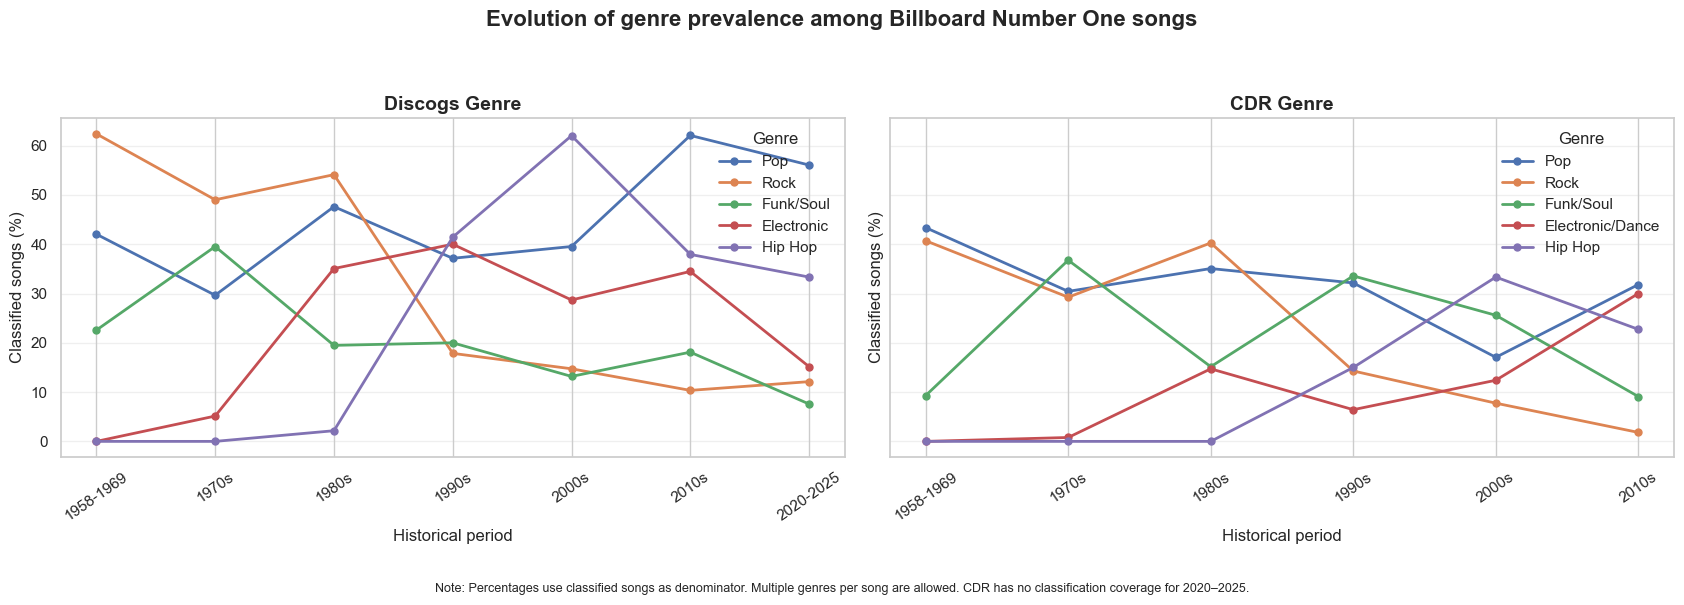

In [83]:
# Celda 27 — Evolución temporal de los géneros

import matplotlib.pyplot as plt
import numpy as np

# Géneros seleccionados para la comparación.
discogs_genres = [
    "Pop",
    "Rock",
    "Funk/Soul",
    "Electronic",
    "Hip Hop",
]

cdr_genres = [
    "Pop",
    "Rock",
    "Funk/Soul",
    "Electronic/Dance",
    "Hip Hop",
]

fig, axes = plt.subplots(
    nrows=1,
    ncols=2,
    figsize=(17, 6),
    sharey=True
)

plot_configs = [
    {
        "ax": axes[0],
        "source": "Discogs Genre",
        "genres": discogs_genres,
        "title": "Discogs Genre",
    },
    {
        "ax": axes[1],
        "source": "CDR Genre",
        "genres": cdr_genres,
        "title": "CDR Genre",
    },
]

for config in plot_configs:
    ax = config["ax"]
    matrix = genre_matrices[config["source"]]

    for genre in config["genres"]:
        if genre not in matrix.index:
            continue

        values = matrix.loc[genre].reindex(period_labels)

        ax.plot(
            period_labels,
            values,
            marker="o",
            linewidth=2,
            markersize=5,
            label=genre
        )

    ax.set_title(config["title"], fontsize=14, fontweight="bold")
    ax.set_xlabel("Historical period")
    ax.set_ylabel("Classified songs (%)")
    ax.tick_params(axis="x", rotation=35)
    ax.grid(axis="y", alpha=0.3)
    ax.legend(title="Genre", frameon=False)

fig.suptitle(
    "Evolution of genre prevalence among Billboard Number One songs",
    fontsize=16,
    fontweight="bold"
)

fig.text(
    0.5,
    0.01,
    "Note: Percentages use classified songs as denominator. "
    "Multiple genres per song are allowed. "
    "CDR has no classification coverage for 2020–2025.",
    ha="center",
    fontsize=9
)

plt.tight_layout(rect=[0, 0.06, 1, 0.93])
plt.show()

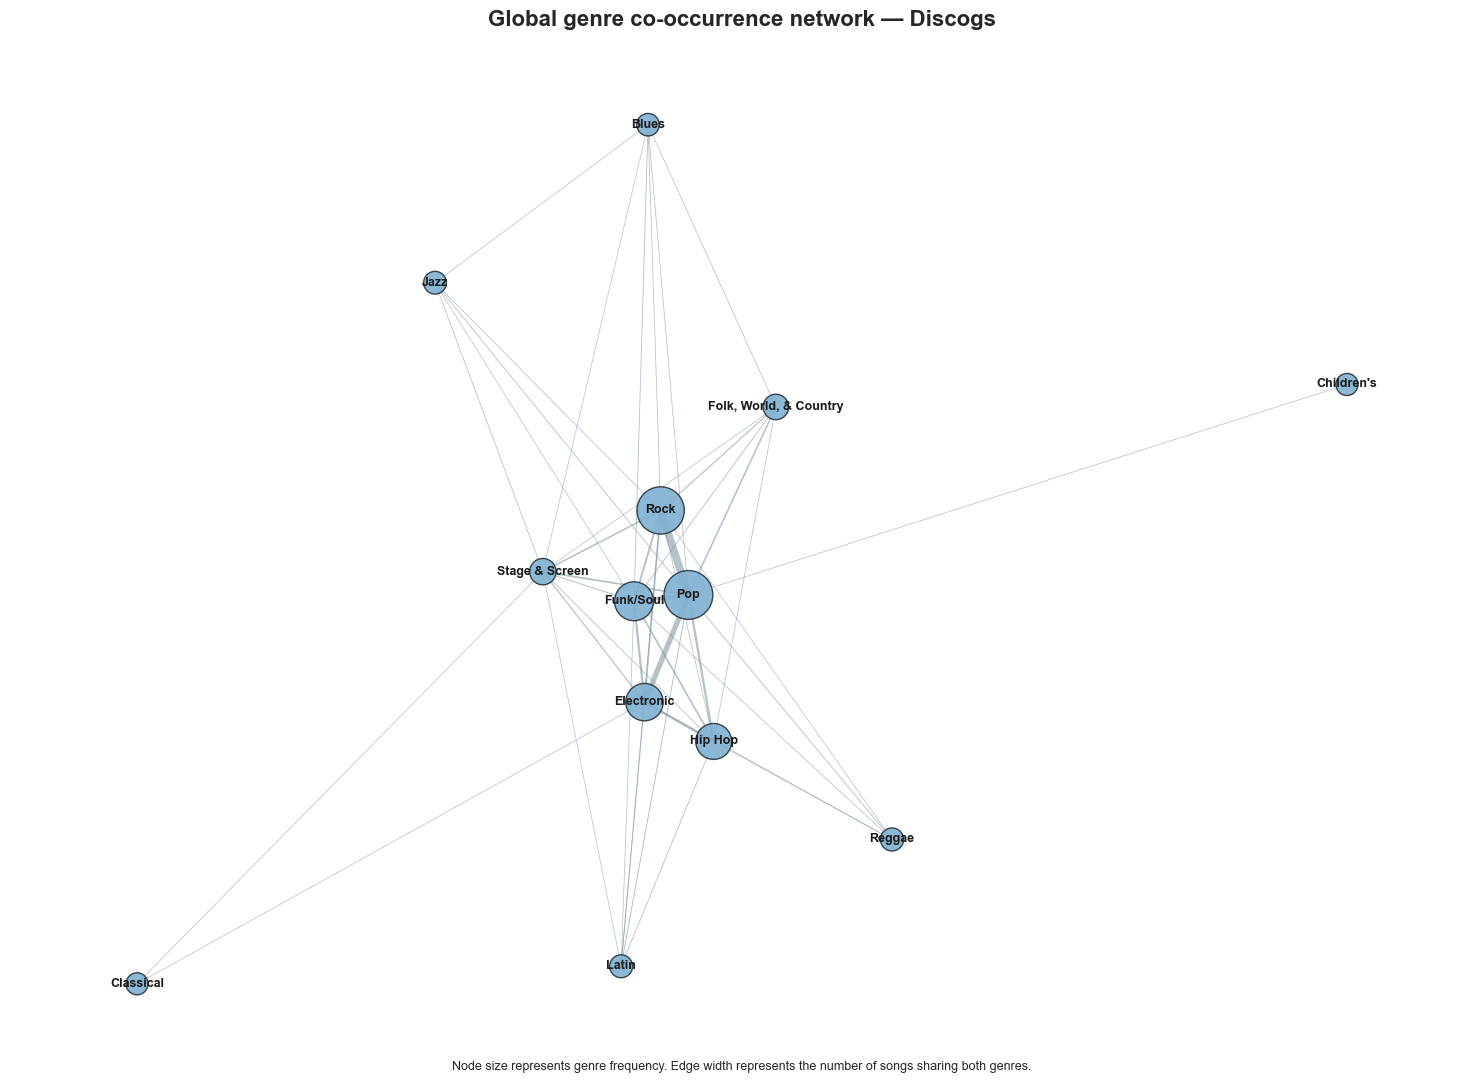

In [85]:
## Celda 28 — Red global de coocurrencias
import networkx as nx
import matplotlib.pyplot as plt
import numpy as np

# Recuperar las relaciones globales de Discogs.
discogs_edges = genre_networks["Discogs Genre"]["edges"]

# Recuperar las frecuencias de cada género desde el dataset limpio.
discogs_tags = tag_datasets_clean["Discogs Genre"]

discogs_node_counts = (
    discogs_tags
    .groupby("Tag_Canonical")["Record_ID"]
    .nunique()
    .to_dict()
)

# Construir el grafo.
G = nx.Graph()

for genre, count in discogs_node_counts.items():
    G.add_node(genre, frequency=count)

for _, edge in discogs_edges.iterrows():
    G.add_edge(
        edge["Source"],
        edge["Target"],
        weight=edge["Weight"]
    )

# Calcular posiciones una sola vez.
# Estas posiciones se reutilizarán en las redes por período.
pos = nx.spring_layout(
    G,
    seed=42,
    weight="weight",
    k=1.2,
    iterations=200
)

# Tamaño de nodos según frecuencia.
node_sizes = [
    250 + G.nodes[node]["frequency"] * 2
    for node in G.nodes()
]

# Grosor de aristas según coocurrencia.
max_weight = max(
    (data["weight"] for _, _, data in G.edges(data=True)),
    default=1
)

edge_widths = [
    0.5 + 5 * (data["weight"] / max_weight)
    for _, _, data in G.edges(data=True)
]

plt.figure(figsize=(15, 11))

nx.draw_networkx_nodes(
    G,
    pos,
    node_size=node_sizes,
    node_color="#80B1D3",
    edgecolors="#263238",
    linewidths=1,
    alpha=0.9
)

nx.draw_networkx_edges(
    G,
    pos,
    width=edge_widths,
    edge_color="#78909C",
    alpha=0.55
)

nx.draw_networkx_labels(
    G,
    pos,
    font_size=9,
    font_weight="bold"
)

plt.title(
    "Global genre co-occurrence network — Discogs",
    fontsize=16,
    fontweight="bold"
)

plt.figtext(
    0.5,
    0.02,
    "Node size represents genre frequency. "
    "Edge width represents the number of songs sharing both genres.",
    ha="center",
    fontsize=9
)

plt.axis("off")
plt.tight_layout()
plt.show()

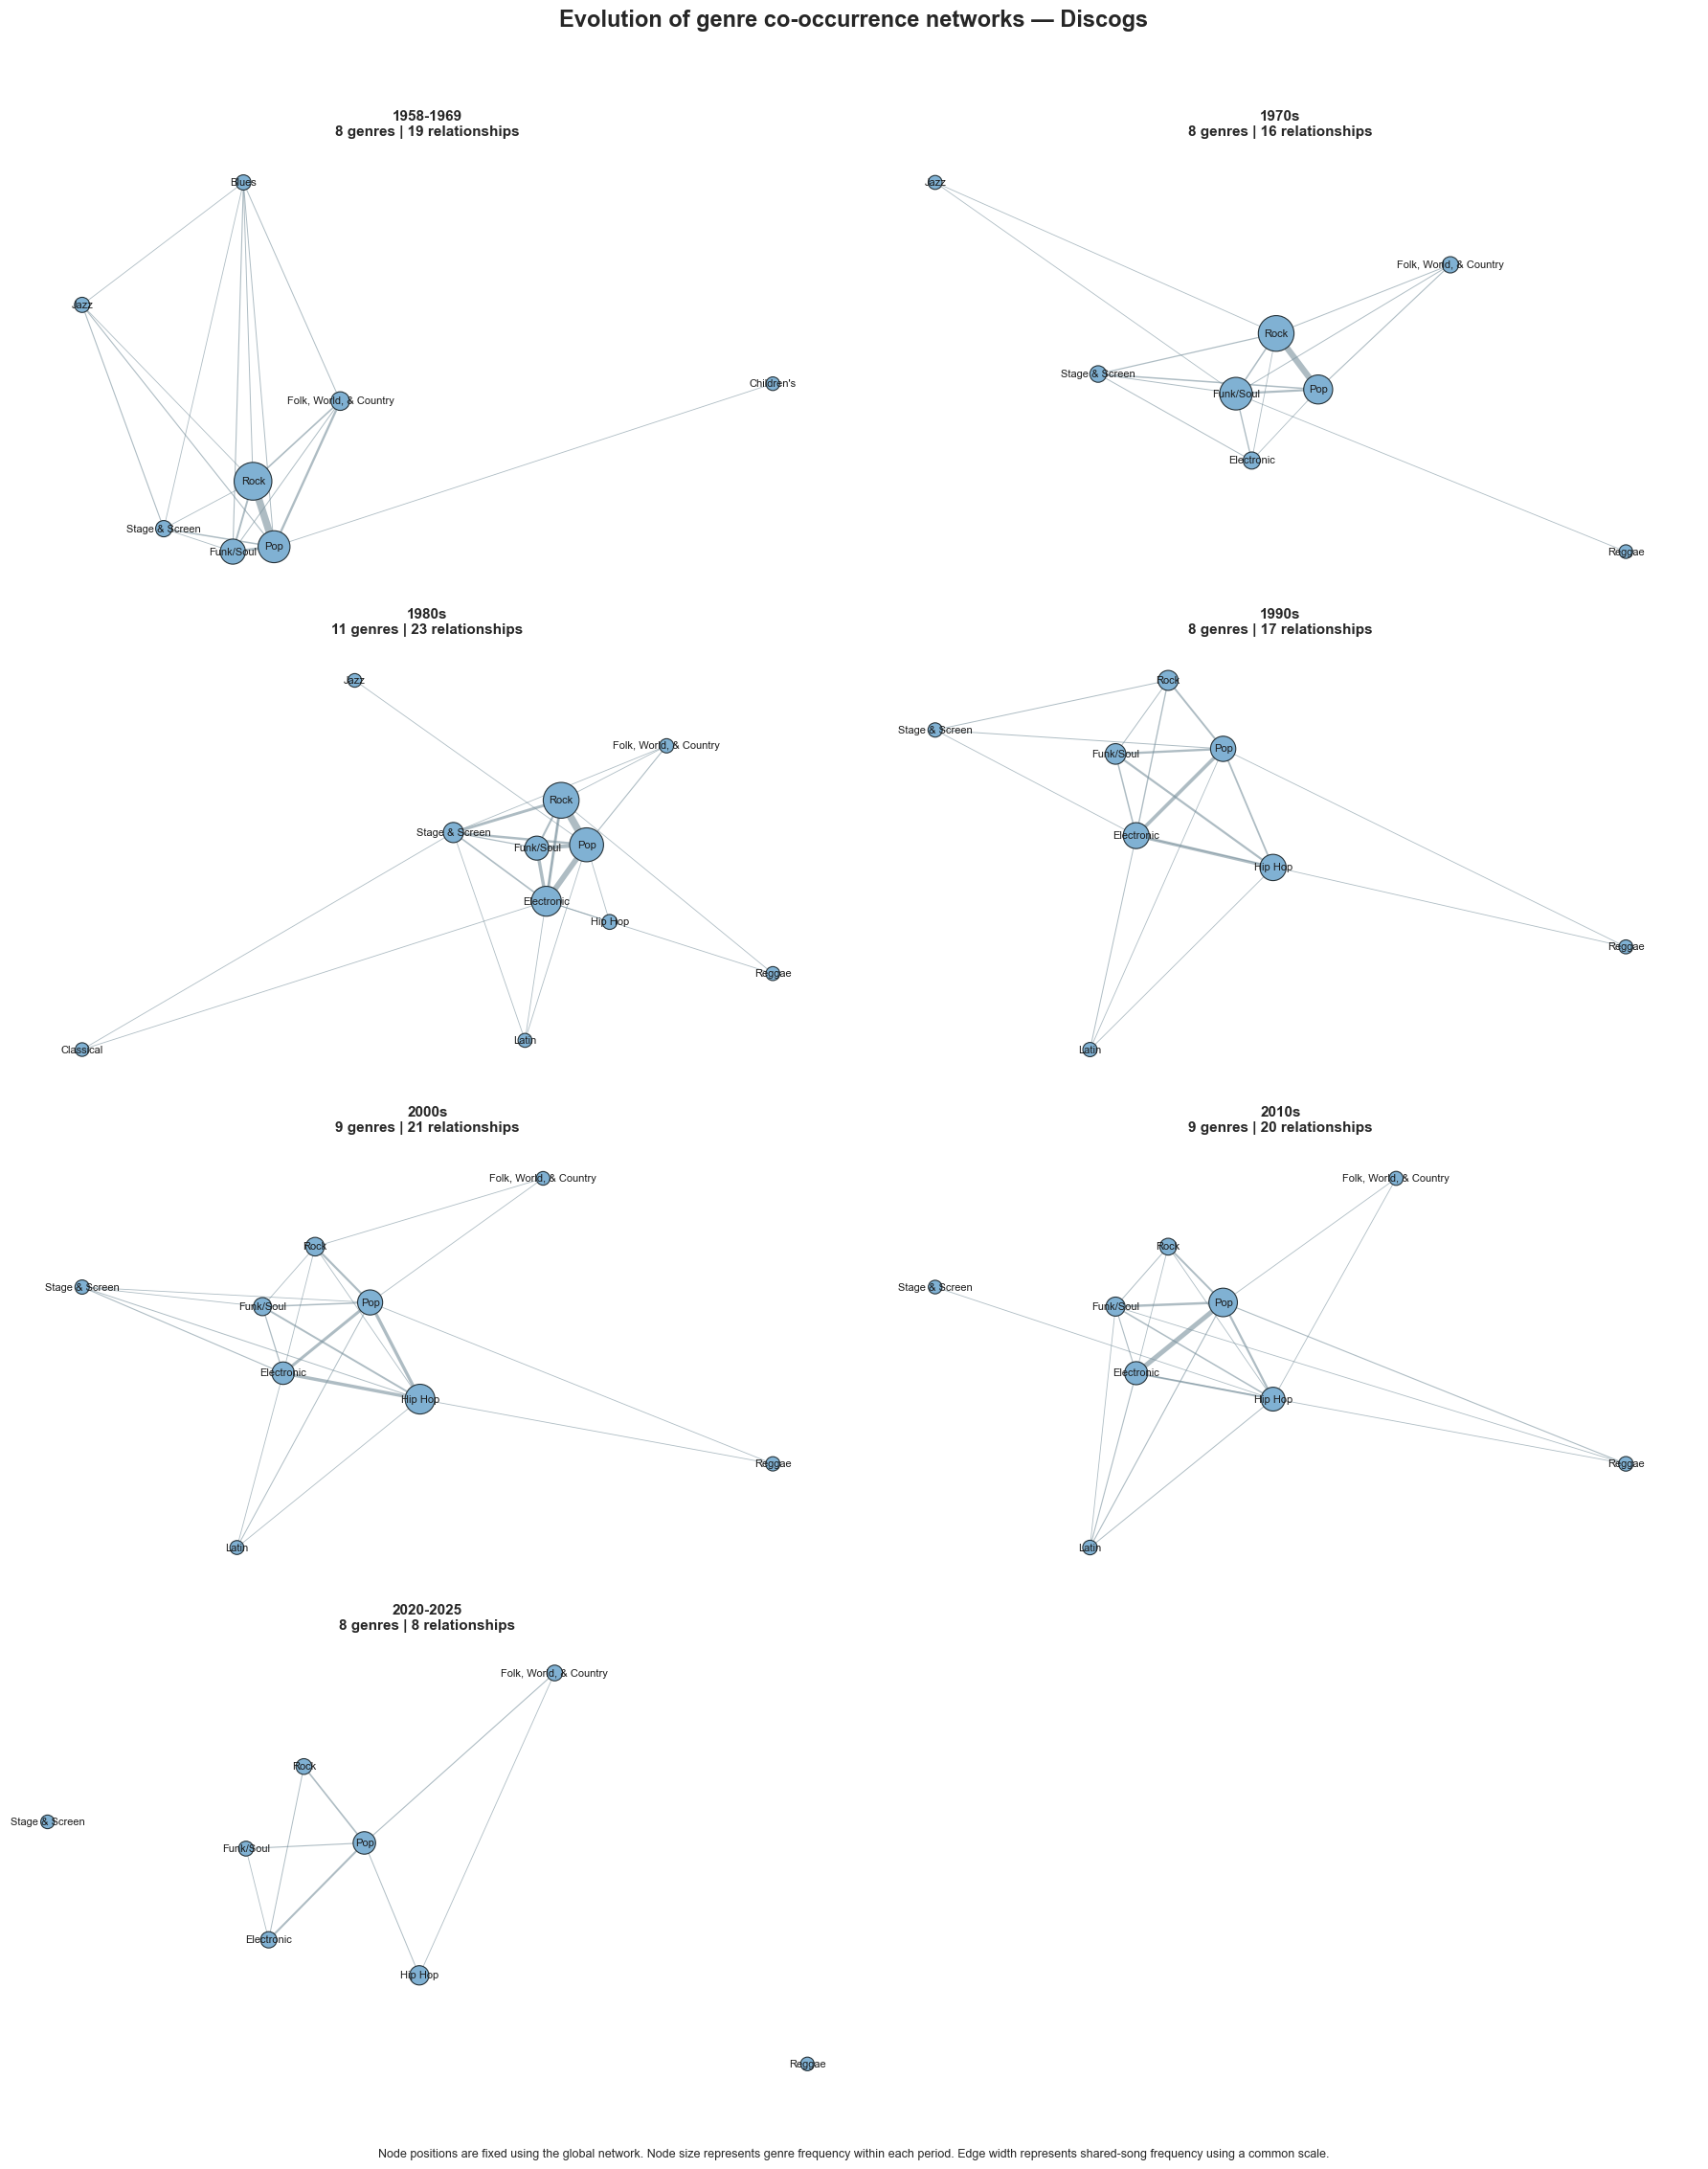

In [87]:
## Celda 29 — Redes comparativas por período

from matplotlib.lines import Line2D

# Relaciones por período.
discogs_edges_by_epoch = (
    genre_networks["Discogs Genre"]["edges_by_epoch"]
)

# Frecuencia de cada género dentro de cada período.
discogs_epoch_tags = tag_datasets_clean["Discogs Genre"]

epoch_node_counts = (
    discogs_epoch_tags
    .groupby(["Epoch", "Tag_Canonical"], observed=True)["Record_ID"]
    .nunique()
    .to_dict()
)

# Escala común para los grosores de las aristas.
global_max_weight = discogs_edges_by_epoch["Weight"].max()

fig, axes = plt.subplots(
    nrows=4,
    ncols=2,
    figsize=(18, 23)
)

axes = axes.flatten()

for i, epoch in enumerate(period_labels):
    ax = axes[i]

    epoch_edges = discogs_edges_by_epoch[
        discogs_edges_by_epoch["Epoch"] == epoch
    ]

    # Construir la red del período.
    G_epoch = nx.Graph()

    # Añadir géneros presentes en ese período.
    for genre in discogs_node_counts:
        count = epoch_node_counts.get((epoch, genre), 0)

        if count > 0:
            G_epoch.add_node(genre, frequency=count)

    # Añadir relaciones observadas.
    for _, edge in epoch_edges.iterrows():
        G_epoch.add_edge(
            edge["Source"],
            edge["Target"],
            weight=edge["Weight"]
        )

    # Solo dibujar los nodos que aparecen en el período.
    active_nodes = list(G_epoch.nodes())

    node_sizes_epoch = [
        100 + G_epoch.nodes[node]["frequency"] * 5
        for node in active_nodes
    ]

    edge_widths_epoch = [
        0.5 + 5 * (data["weight"] / global_max_weight)
        for _, _, data in G_epoch.edges(data=True)
    ]

    # Reutilizar las posiciones de la red global.
    nx.draw_networkx_nodes(
        G_epoch,
        pos,
        nodelist=active_nodes,
        node_size=node_sizes_epoch,
        node_color="#80B1D3",
        edgecolors="#263238",
        linewidths=0.8,
        ax=ax
    )

    nx.draw_networkx_edges(
        G_epoch,
        pos,
        width=edge_widths_epoch,
        edge_color="#78909C",
        alpha=0.6,
        ax=ax
    )

    nx.draw_networkx_labels(
        G_epoch,
        pos,
        font_size=8,
        ax=ax
    )

    ax.set_title(
        f"{epoch}\n"
        f"{G_epoch.number_of_nodes()} genres | "
        f"{G_epoch.number_of_edges()} relationships",
        fontsize=11,
        fontweight="bold"
    )

    ax.axis("off")

# Eliminar el panel sobrante.
axes[-1].axis("off")

fig.suptitle(
    "Evolution of genre co-occurrence networks — Discogs",
    fontsize=17,
    fontweight="bold",
    y=0.99
)

fig.text(
    0.5,
    0.015,
    "Node positions are fixed using the global network. "
    "Node size represents genre frequency within each period. "
    "Edge width represents shared-song frequency using a common scale.",
    ha="center",
    fontsize=9
)

plt.tight_layout(rect=[0, 0.04, 1, 0.97])
plt.show()

In [101]:
## Celda 30 — Indicadores explicativos de la red global

# Número de géneros diferentes conectados a cada nodo.
degree = dict(G.degree())

# Suma de los pesos de todas las conexiones de cada nodo.
strength = dict(G.degree(weight="weight"))

# Frecuencia individual de cada género.
genre_frequency = nx.get_node_attributes(G, "frequency")

# Porcentaje de canciones clasificadas que contienen cada género.
total_classified_songs = (
    discogs_tags["Record_ID"].nunique()
)

node_explainability = pd.DataFrame({
    "Genre": list(G.nodes()),
    "Song_Count": [
        genre_frequency[node] for node in G.nodes()
    ],
    "Song_Prevalence": [
        genre_frequency[node] / total_classified_songs * 100
        for node in G.nodes()
    ],
    "Connected_Genres": [
        degree[node] for node in G.nodes()
    ],
    "Cooccurrence_Strength": [
        strength[node] for node in G.nodes()
    ],
})

node_explainability = (
    node_explainability
    .sort_values(
        ["Cooccurrence_Strength", "Song_Count"],
        ascending=False
    )
    .reset_index(drop=True)
)

display(
    node_explainability.round(2)
)

,Genre,Song_Count,Song_Prevalence,Connected_Genres,Cooccurrence_Strength
0,Pop,492,42.38,11,486
1,Rock,454,39.10,10,275
2,Electronic,237,20.41,8,253
3,Funk/Soul,267,23.00,10,196
4,Hip Hop,209,18.00,8,128
5,Stage & Screen,55,4.74,10,82
6,"Folk, World, & Country",43,3.70,6,43
7,Latin,11,0.95,6,20
8,Reggae,13,1.12,5,12
9,Jazz,9,0.78,5,11


In [103]:
## Celda 31 — Ranking de coocurrencias globales

edge_explainability = discogs_edges.copy()

edge_explainability["Classified_Songs"] = total_classified_songs

edge_explainability["Cooccurrence_Percentage"] = (
    edge_explainability["Weight"]
    / edge_explainability["Classified_Songs"]
    * 100
)

edge_explainability = (
    edge_explainability
    .rename(columns={
        "Source": "Genre_A",
        "Target": "Genre_B",
        "Weight": "Shared_Songs",
    })
    [[
        "Genre_A",
        "Genre_B",
        "Shared_Songs",
        "Classified_Songs",
        "Cooccurrence_Percentage",
    ]]
    .sort_values(
        "Shared_Songs",
        ascending=False
    )
    .reset_index(drop=True)
)

display(
    edge_explainability.head(15).round(2)
)

,Genre_A,Genre_B,Shared_Songs,Classified_Songs,Cooccurrence_Percentage
0,Pop,Rock,177,1161,15.25
1,Electronic,Pop,116,1161,9.99
2,Funk/Soul,Pop,82,1161,7.06
3,Electronic,Hip Hop,49,1161,4.22
4,Hip Hop,Pop,41,1161,3.53
5,Electronic,Funk/Soul,39,1161,3.36
6,Funk/Soul,Rock,30,1161,2.58
7,Pop,Stage & Screen,28,1161,2.41
8,Funk/Soul,Hip Hop,26,1161,2.24
9,Electronic,Rock,26,1161,2.24


In [105]:
## Celda 32 — Evolución temporal de las coocurrencias

# Número de canciones clasificadas por período.
classified_by_epoch = (
    discogs_tags
    .groupby("Epoch", observed=True)["Record_ID"]
    .nunique()
)

temporal_edges = discogs_edges_by_epoch.copy()

temporal_edges["Classified_Songs"] = (
    temporal_edges["Epoch"]
    .map(classified_by_epoch.to_dict())
    .astype("int64")
)

temporal_edges["Cooccurrence_Percentage"] = (
    temporal_edges["Weight"]
    / temporal_edges["Classified_Songs"]
    * 100
)

temporal_edges["Genre_Pair"] = (
    temporal_edges["Source"]
    + " + "
    + temporal_edges["Target"]
)

temporal_edges = temporal_edges.sort_values(
    ["Epoch", "Weight"],
    ascending=[True, False]
)

display(
    temporal_edges[
        [
            "Epoch",
            "Genre_Pair",
            "Weight",
            "Classified_Songs",
            "Cooccurrence_Percentage",
        ]
    ].round(2)
)

,Epoch,Genre_Pair,Weight,Classified_Songs,Cooccurrence_Percentage
107,1958-1969,Pop + Rock,50,226,22.12
61,1958-1969,Funk/Soul + Pop,14,226,6.19
45,1958-1969,"Folk, World, & Country + Pop",12,226,5.31
70,1958-1969,Funk/Soul + Rock,9,226,3.98
51,1958-1969,"Folk, World, & Country + Rock",7,226,3.10
...,...,...,...,...,...
67,2020-2025,Funk/Soul + Pop,3,66,4.55
36,2020-2025,Electronic + Rock,2,66,3.03
87,2020-2025,Hip Hop + Pop,2,66,3.03
14,2020-2025,Electronic + Funk/Soul,1,66,1.52


In [107]:
## Celda 33 — Asociación dominante por período

dominant_edges = (
    temporal_edges
    .sort_values(
        ["Epoch", "Weight"],
        ascending=[True, False]
    )
    .groupby("Epoch", observed=True)
    .head(1)
    [[
        "Epoch",
        "Genre_Pair",
        "Weight",
        "Classified_Songs",
        "Cooccurrence_Percentage",
    ]]
    .reset_index(drop=True)
)

display(dominant_edges.round(2))

,Epoch,Genre_Pair,Weight,Classified_Songs,Cooccurrence_Percentage
0,1958-1969,Pop + Rock,50,226,22.12
1,1970s,Pop + Rock,41,253,16.21
2,1980s,Pop + Rock,50,231,21.65
3,1990s,Electronic + Pop,21,140,15.00
4,2000s,Electronic + Hip Hop,20,129,15.50
5,2010s,Electronic + Pop,31,116,26.72
6,2020-2025,Electronic + Pop,10,66,15.15


In [109]:
## Celda 34 — Red global interactiva con PyVis

from pyvis.network import Network
from IPython.display import HTML, display

net = Network(
    height="750px",
    width="100%",
    bgcolor="#FFFFFF",
    font_color="#263238",
    directed=False,
    notebook=True
)

# Desactivar la física para conservar las posiciones
# calculadas previamente con NetworkX.
net.toggle_physics(False)

# Agregar nodos con información explicativa.
for node, attributes in G.nodes(data=True):

    frequency = attributes["frequency"]
    prevalence = frequency / total_classified_songs * 100

    net.add_node(
        node,
        label=node,
        title=(
            f"<b>{node}</b><br>"
            f"Songs: {frequency}<br>"
            f"Prevalence: {prevalence:.2f}%<br>"
            f"Connected genres: {degree[node]}<br>"
            f"Co-occurrence strength: {strength[node]}"
        ),
        size=15 + frequency * 0.12,
        color="#80B1D3",
        x=float(pos[node][0] * 1000),
        y=float(pos[node][1] * 1000),
        physics=False
    )

# Agregar conexiones con información explicativa.
for source, target, attributes in G.edges(data=True):

    weight = attributes["weight"]
    percentage = weight / total_classified_songs * 100

    net.add_edge(
        source,
        target,
        value=weight,
        title=(
            f"<b>{source} + {target}</b><br>"
            f"Shared songs: {weight}<br>"
            f"Prevalence: {percentage:.2f}%"
        ),
        color="#90A4AE"
    )

# Mostrar la red.
display(HTML(net.generate_html()))

In [111]:

## Celda 35 — Métricas de asociación: Jaccard y Lift

# Universo de canciones clasificadas por Discogs.
# Cada canción debe contar una sola vez por género.
genre_records = (
    discogs_tags[
        ["Record_ID", "Tag_Canonical"]
    ]
    .dropna()
    .drop_duplicates()
)

total_songs = genre_records["Record_ID"].nunique()

# Frecuencia individual de cada género.
genre_counts = (
    genre_records
    .groupby("Tag_Canonical")["Record_ID"]
    .nunique()
)

# Recuperar las coocurrencias globales.
association_metrics = discogs_edges.copy()

# Incorporar frecuencias individuales de cada género.
association_metrics["Genre_A_Count"] = (
    association_metrics["Source"].map(genre_counts)
)

association_metrics["Genre_B_Count"] = (
    association_metrics["Target"].map(genre_counts)
)

association_metrics["Classified_Songs"] = total_songs

# Probabilidades individuales.
association_metrics["Genre_A_Prevalence"] = (
    association_metrics["Genre_A_Count"] / total_songs
)

association_metrics["Genre_B_Prevalence"] = (
    association_metrics["Genre_B_Count"] / total_songs
)

# Probabilidad observada de coocurrencia.
association_metrics["Joint_Prevalence"] = (
    association_metrics["Weight"] / total_songs
)

# Jaccard: intersección / unión.
association_metrics["Jaccard"] = (
    association_metrics["Weight"]
    / (
        association_metrics["Genre_A_Count"]
        + association_metrics["Genre_B_Count"]
        - association_metrics["Weight"]
    )
)

# Lift: probabilidad observada / probabilidad esperada.
association_metrics["Expected_Shared_Songs"] = (
    association_metrics["Genre_A_Count"]
    * association_metrics["Genre_B_Count"]
    / total_songs
)

association_metrics["Lift"] = (
    association_metrics["Weight"]
    / association_metrics["Expected_Shared_Songs"]
)

# Clasificación descriptiva de la asociación.
association_metrics["Association_Type"] = np.select(
    [
        association_metrics["Lift"] > 1,
        association_metrics["Lift"] < 1,
    ],
    [
        "Positive association",
        "Negative association",
    ],
    default="Approximately independent"
)

# Preparar tabla final.
association_metrics = (
    association_metrics
    .rename(columns={
        "Source": "Genre_A",
        "Target": "Genre_B",
        "Weight": "Shared_Songs",
    })
    [[
        "Genre_A",
        "Genre_B",
        "Shared_Songs",
        "Genre_A_Count",
        "Genre_B_Count",
        "Jaccard",
        "Expected_Shared_Songs",
        "Lift",
        "Association_Type",
    ]]
    .sort_values("Lift", ascending=False)
    .reset_index(drop=True)
)

display(association_metrics.round({
    "Jaccard": 4,
    "Expected_Shared_Songs": 2,
    "Lift": 3,
}))


,Genre_A,Genre_B,Shared_Songs,Genre_A_Count,Genre_B_Count,Jaccard,Expected_Shared_Songs,Lift,Association_Type
0,Blues,Jazz,1,6,9,0.0714,0.05,21.500,Positive association
1,Classical,Stage & Screen,1,1,55,0.0182,0.05,21.109,Positive association
2,Blues,"Folk, World, & Country",2,6,43,0.0426,0.22,9.000,Positive association
3,Jazz,Stage & Screen,3,9,55,0.0492,0.43,7.036,Positive association
4,Classical,Electronic,1,1,237,0.0042,0.20,4.899,Positive association
5,Blues,Stage & Screen,1,6,55,0.0167,0.28,3.518,Positive association
6,Electronic,Latin,6,237,11,0.0248,2.25,2.672,Positive association
7,Children's,Pop,1,1,492,0.0020,0.42,2.360,Positive association
8,Blues,Funk/Soul,3,6,267,0.0111,1.38,2.174,Positive association
9,Hip Hop,Latin,4,209,11,0.0185,1.98,2.020,Positive association


In [119]:
# Minimum support required for exploratory interpretation
MIN_SHARED_SONGS = 5

supported_associations = association_metrics.loc[
    association_metrics["Shared_Songs"] >= MIN_SHARED_SONGS
].copy()

# More neutral interpretation of Lift
supported_associations["Association_Type"] = np.select(
    [
        supported_associations["Lift"] > 1.001,
        supported_associations["Lift"] < 0.999,
    ],
    [
        "Above independence expectation",
        "Below independence expectation",
    ],
    default="Approximately independent",
)

# Associations appearing more frequently than expected
top_positive_associations = (
    supported_associations.loc[
        supported_associations["Lift"] > 1
    ]
    .sort_values("Lift", ascending=False)
    .head(15)
)

# Associations appearing less frequently than expected
top_negative_associations = (
    supported_associations.loc[
        supported_associations["Lift"] < 1
    ]
    .sort_values("Lift", ascending=True)
    .head(15)
)

# Most recurrent combinations, regardless of Lift
top_jaccard_associations = (
    supported_associations
    .sort_values("Jaccard", ascending=False)
    .head(15)
)

display(
    top_jaccard_associations[
        [
            "Genre_A",
            "Genre_B",
            "Shared_Songs",
            "Jaccard",
            "Lift",
            "Association_Type",
        ]
    ].round(3)
)


,Genre_A,Genre_B,Shared_Songs,Jaccard,Lift,Association_Type
20,Pop,Rock,177,0.230,0.920,Below independence expectation
15,Electronic,Pop,116,0.189,1.155,Above independence expectation
16,Electronic,Hip Hop,49,0.123,1.149,Above independence expectation
24,Funk/Soul,Pop,82,0.121,0.725,Below independence expectation
25,Electronic,Funk/Soul,39,0.084,0.716,Below independence expectation
33,Hip Hop,Pop,41,0.062,0.463,Below independence expectation
30,Funk/Soul,Hip Hop,26,0.058,0.541,Below independence expectation
13,Pop,Stage & Screen,28,0.054,1.201,Above independence expectation
18,Rock,Stage & Screen,23,0.047,1.069,Above independence expectation
14,Electronic,Stage & Screen,13,0.047,1.158,Above independence expectation


In [121]:
# Inspect temporal network structures

for source, network in genre_networks.items():
    print(f"\n{'=' * 60}")
    print(f"SOURCE: {source}")
    print("=" * 60)

    print("\nNodes by epoch:")
    print(network["nodes_by_epoch"].head())
    print("\nColumns:", network["nodes_by_epoch"].columns.tolist())

    print("\nEdges by epoch:")
    print(network["edges_by_epoch"].head())
    print("\nColumns:", network["edges_by_epoch"].columns.tolist())


SOURCE: CDR Genre

Nodes by epoch:
                Tag  Song_Count
0             Blues           1
1           Calypso           1
2         Classical           1
3  Electronic/Dance          94
4      Folk/Country          30

Columns: ['Tag', 'Song_Count']

Edges by epoch:
             Source            Target  Epoch  Weight
0           Calypso               Pop  1980s       1
1         Classical  Electronic/Dance  1980s       1
2  Electronic/Dance         Funk/Soul  1980s       2
3  Electronic/Dance           Hip Hop  1990s       1
4  Electronic/Dance             Latin  1990s       1

Columns: ['Source', 'Target', 'Epoch', 'Weight']

SOURCE: Discogs Genre

Nodes by epoch:
                      Tag  Song_Count
0                   Blues           6
1              Children's           1
2               Classical           1
3              Electronic         237
4  Folk, World, & Country          43

Columns: ['Tag', 'Song_Count']

Edges by epoch:
  Source                  Target      

In [123]:
## Celda 37 — Frecuencia de géneros por período
# Temporal genre node frequencies

nodes_by_epoch = {}

for source in ["CDR Genre", "Discogs Genre"]:

    tags = tag_datasets_clean[source].copy()

    tags = tags[
        ["Record_ID", "Epoch", "Tag_Canonical"]
    ].dropna()

    tags = tags.drop_duplicates(
        subset=["Record_ID", "Epoch", "Tag_Canonical"]
    )

    temporal_nodes = (
        tags.groupby(
            ["Epoch", "Tag_Canonical"],
            observed=True
        )["Record_ID"]
        .nunique()
        .reset_index(name="Song_Count")
        .rename(columns={"Tag_Canonical": "Tag"})
    )

    nodes_by_epoch[source] = temporal_nodes

    print(f"\n{'=' * 60}")
    print(f"SOURCE: {source}")
    print("=" * 60)

    display(
        temporal_nodes.sort_values(
            ["Epoch", "Song_Count"],
            ascending=[True, False]
        ).head(15)
    )


SOURCE: CDR Genre


,Epoch,Tag,Song_Count
5,1958-1969,Pop,98
6,1958-1969,Rock,92
1,1958-1969,Funk/Soul,21
0,1958-1969,Folk/Country,19
2,1958-1969,Jazz,5
3,1958-1969,March,2
4,1958-1969,Polka,1
9,1970s,Funk/Soul,93
11,1970s,Pop,77
13,1970s,Rock,74



SOURCE: Discogs Genre


,Epoch,Tag,Song_Count
6,1958-1969,Rock,141
5,1958-1969,Pop,95
3,1958-1969,Funk/Soul,51
2,1958-1969,"Folk, World, & Country",19
7,1958-1969,Stage & Screen,10
0,1958-1969,Blues,6
4,1958-1969,Jazz,6
1,1958-1969,Children's,1
14,1970s,Rock,124
10,1970s,Funk/Soul,100


In [125]:
## Celda 38 — Métricas temporales de asociación

def calculate_temporal_associations(
    tag_data,
    edges_by_epoch
):
    records = []

    for epoch, epoch_edges in edges_by_epoch.groupby(
        "Epoch",
        observed=True
    ):

        epoch_tags = tag_data.loc[
            tag_data["Epoch"] == epoch,
            ["Record_ID", "Tag_Canonical"]
        ].dropna().drop_duplicates()

        total_songs = epoch_tags["Record_ID"].nunique()

        genre_counts = (
            epoch_tags.groupby("Tag_Canonical")["Record_ID"]
            .nunique()
        )

        for _, edge in epoch_edges.iterrows():

            genre_a = edge["Source"]
            genre_b = edge["Target"]
            shared = int(edge["Weight"])

            count_a = int(genre_counts.get(genre_a, 0))
            count_b = int(genre_counts.get(genre_b, 0))

            union = count_a + count_b - shared

            expected = (
                count_a * count_b / total_songs
                if total_songs > 0 else np.nan
            )

            jaccard = shared / union if union > 0 else np.nan

            lift = (
                shared / expected
                if expected > 0 else np.nan
            )

            records.append({
                "Epoch": epoch,
                "Genre_A": genre_a,
                "Genre_B": genre_b,
                "Shared_Songs": shared,
                "Genre_A_Count": count_a,
                "Genre_B_Count": count_b,
                "Classified_Songs": total_songs,
                "Jaccard": jaccard,
                "Lift": lift,
            })

    return pd.DataFrame(records)

In [127]:
discogs_temporal_associations = calculate_temporal_associations(
    tag_datasets_clean["Discogs Genre"],
    genre_networks["Discogs Genre"]["edges_by_epoch"]
)

display(
    discogs_temporal_associations.sort_values(
        ["Epoch", "Shared_Songs"],
        ascending=[True, False]
    ).head(20)
)

,Epoch,Genre_A,Genre_B,Shared_Songs,Genre_A_Count,Genre_B_Count,Classified_Songs,Jaccard,Lift
16,1958-1969,Pop,Rock,50,95,141,226,0.268817,0.843598
10,1958-1969,Funk/Soul,Pop,14,51,95,226,0.106061,0.653044
8,1958-1969,"Folk, World, & Country",Pop,12,19,95,226,0.117647,1.502493
11,1958-1969,Funk/Soul,Rock,9,51,141,226,0.049180,0.282854
9,1958-1969,"Folk, World, & Country",Rock,7,19,141,226,0.045752,0.590519
17,1958-1969,Pop,Stage & Screen,6,95,10,226,0.060606,1.427368
1,1958-1969,Blues,Funk/Soul,3,6,51,226,0.055556,2.215686
13,1958-1969,Jazz,Pop,3,6,95,226,0.030612,1.189474
15,1958-1969,Jazz,Stage & Screen,3,6,10,226,0.230769,11.300000
0,1958-1969,Blues,"Folk, World, & Country",2,6,19,226,0.086957,3.964912


In [129]:
cdr_temporal_associations = calculate_temporal_associations(
    tag_datasets_clean["CDR Genre"],
    genre_networks["CDR Genre"]["edges_by_epoch"]
)

display(
    cdr_temporal_associations.sort_values(
        ["Epoch", "Shared_Songs"],
        ascending=[True, False]
    ).head(20)
)

,Epoch,Genre_A,Genre_B,Shared_Songs,Genre_A_Count,Genre_B_Count,Classified_Songs,Jaccard,Lift
4,1958-1969,Funk/Soul,Rock,4,21,92,226,0.036697,0.467909
1,1958-1969,Folk/Country,Pop,3,19,98,226,0.026316,0.364125
5,1958-1969,Pop,Rock,2,98,92,226,0.010638,0.050133
0,1958-1969,Folk/Country,March,1,19,2,226,0.050000,5.947368
2,1958-1969,Folk/Country,Rock,1,19,92,226,0.009091,0.129291
3,1958-1969,Funk/Soul,Jazz,1,21,5,226,0.040000,2.152381
8,1970s,Funk/Soul,Rock,2,93,74,253,0.012121,0.073525
6,1970s,Folk/Country,Rock,1,9,74,253,0.012195,0.379880
7,1970s,Funk/Soul,Pop,1,93,77,253,0.005917,0.035330
15,1980s,Funk/Soul,Rock,7,35,93,231,0.057851,0.496774


In [131]:
# Validate temporal association metrics

for source, associations in [
    ("Discogs Genre", discogs_temporal_associations),
    ("CDR Genre", cdr_temporal_associations),
]:

    if associations.empty:
        print(f"{source}: no temporal associations found.")
        continue

    assert (
        associations["Shared_Songs"]
        <= associations[["Genre_A_Count", "Genre_B_Count"]].min(axis=1)
    ).all()

    assert associations["Jaccard"].between(0, 1).all()

    assert (associations["Lift"] > 0).all()

    print(f"{source}: all validations passed.")

Discogs Genre: all validations passed.
CDR Genre: all validations passed.


In [133]:
## Celda 39 — Preparar posiciones globales de los nodos
import networkx as nx
import plotly.graph_objects as go
import plotly.express as px
import ipywidgets as widgets

from IPython.display import display, clear_output

# Select the main taxonomy
SOURCE = "Discogs Genre"

temporal_nodes = nodes_by_epoch[SOURCE].copy()
temporal_edges = genre_networks[SOURCE]["edges_by_epoch"].copy()
temporal_metrics = discogs_temporal_associations.copy()

# Build aggregate graph to calculate fixed node positions
G = nx.Graph()

global_nodes = genre_networks[SOURCE]["nodes"]

for _, row in global_nodes.iterrows():
    G.add_node(row["Tag"])

for _, row in genre_networks[SOURCE]["edges"].iterrows():
    G.add_edge(
        row["Source"],
        row["Target"],
        weight=row["Weight"]
    )

# Calculate positions only once
pos = nx.spring_layout(
    G,
    seed=42,
    weight="weight",
    k=1.2,
    iterations=200
)

# Stable genre colors
genres = sorted(G.nodes())

palette = px.colors.qualitative.Plotly

genre_colors = {
    genre: palette[i % len(palette)]
    for i, genre in enumerate(genres)
}

print(f"Nodes: {G.number_of_nodes()}")
print(f"Edges: {G.number_of_edges()}")
print("Fixed node positions calculated.")

Nodes: 13
Edges: 44
Fixed node positions calculated.


In [135]:
## Celda 40 — Función para construir la red interactiva

def plot_genre_network(
    epoch,
    metric="Shared_Songs",
    min_support=2
):
    # Filter nodes for selected period
    period_nodes = temporal_nodes.loc[
        temporal_nodes["Epoch"] == epoch
    ].copy()

    if period_nodes.empty:
        print(f"No classified genres available for {epoch}.")
        return

    # Filter associations for selected period
    period_edges = temporal_metrics.loc[
        temporal_metrics["Epoch"] == epoch
    ].copy()

    period_edges = period_edges.loc[
        period_edges["Shared_Songs"] >= min_support
    ].copy()

    # Graph traces
    edge_traces = []

    metric_labels = {
        "Shared_Songs": "Shared songs",
        "Jaccard": "Jaccard",
        "Lift": "Lift"
    }

    for _, edge in period_edges.iterrows():

        source = edge["Genre_A"]
        target = edge["Genre_B"]

        x0, y0 = pos[source]
        x1, y1 = pos[target]

        value = edge[metric]

        if metric == "Shared_Songs":
            width = max(1, min(8, value / 5))
        elif metric == "Jaccard":
            width = max(1, min(8, value * 20))
        else:
            width = max(
                1,
                min(8, abs(np.log2(value)) * 2)
            )

        association = (
            "Above independence expectation"
            if edge["Lift"] > 1
            else "Below independence expectation"
            if edge["Lift"] < 1
            else "Approximately independent"
        )

        hover_text = (
            f"<b>{source} + {target}</b><br>"
            f"Shared songs: {edge['Shared_Songs']}<br>"
            f"Jaccard: {edge['Jaccard']:.3f}<br>"
            f"Lift: {edge['Lift']:.3f}<br>"
            f"Association: {association}"
        )

        edge_traces.append(
            go.Scatter(
                x=[x0, x1],
                y=[y0, y1],
                mode="lines",
                line=dict(
                    width=width,
                    color="#8492A6"
                ),
                hoverinfo="text",
                text=[hover_text, hover_text],
                showlegend=False
            )
        )

    # Node information
    node_x = []
    node_y = []
    node_sizes = []
    node_colors = []
    node_text = []

    for _, node in period_nodes.iterrows():

        genre = node["Tag"]
        count = node["Song_Count"]

        x, y = pos[genre]

        node_x.append(x)
        node_y.append(y)
        node_sizes.append(15 + count * 0.12)
        node_colors.append(genre_colors[genre])

        node_text.append(
            f"<b>{genre}</b><br>"
            f"Songs: {count}<br>"
            f"Period: {epoch}"
        )

    node_trace = go.Scatter(
        x=node_x,
        y=node_y,
        mode="markers+text",
        text=period_nodes["Tag"],
        textposition="top center",
        hovertext=node_text,
        hoverinfo="text",
        marker=dict(
            size=node_sizes,
            color=node_colors,
            line=dict(width=1, color="white"),
            opacity=0.9
        ),
        showlegend=False
    )

    fig = go.Figure(
        data=edge_traces + [node_trace]
    )

    fig.update_layout(
        title=(
            f"Discogs Genre Co-occurrence Network — {epoch}"
            f"<br><sup>Edge metric: {metric_labels[metric]}</sup>"
        ),
        template="plotly_white",
        height=750,
        showlegend=False,
        hovermode="closest",
        margin=dict(l=20, r=20, t=80, b=20),
        xaxis=dict(
            showgrid=False,
            zeroline=False,
            showticklabels=False
        ),
        yaxis=dict(
            showgrid=False,
            zeroline=False,
            showticklabels=False
        )
    )

    fig.show()

In [145]:
## Celda 41 — Controles interactivos
from pathlib import Path
import plotly.graph_objects as go
import numpy as np

MIN_SUPPORT = 2

epochs = [
    "1958-1969",
    "1970s",
    "1980s",
    "1990s",
    "2000s",
    "2010s",
    "2020-2025"
]

metrics = {
    "Shared songs": "Shared_Songs",
    "Jaccard": "Jaccard",
    "Lift": "Lift"
}

fig = go.Figure()
visibility_groups = {}
combo_titles = []

# Generate one group of traces per period and metric
for epoch in epochs:

    for metric_label, metric_column in metrics.items():

        period_edges = temporal_metrics.loc[
            (temporal_metrics["Epoch"] == epoch) &
            (temporal_metrics["Shared_Songs"] >= MIN_SUPPORT)
        ].copy()

        period_nodes = temporal_nodes.loc[
            temporal_nodes["Epoch"] == epoch
        ].copy()

        start_index = len(fig.data)

        # If there are no classified songs, create an informative placeholder
        if period_nodes.empty:

            fig.add_trace(
                go.Scatter(
                    x=[0],
                    y=[0],
                    mode="text",
                    text=["No classified songs in this period"],
                    hoverinfo="skip",
                    showlegend=False
                )
            )

        else:

            # Individual edges
            for _, edge in period_edges.iterrows():

                source = edge["Genre_A"]
                target = edge["Genre_B"]

                x0, y0 = pos[source]
                x1, y1 = pos[target]

                value = edge[metric_column]

                if metric_column == "Shared_Songs":
                    width = max(1, min(8, value / 5))
                elif metric_column == "Jaccard":
                    width = max(1, min(8, value * 20))
                else:
                    width = max(
                        1,
                        min(8, abs(np.log2(value)) * 2)
                    )

                fig.add_trace(
                    go.Scatter(
                        x=[x0, x1],
                        y=[y0, y1],
                        mode="lines",
                        line=dict(
                            width=width,
                            color="#8492A6"
                        ),
                        hoverinfo="text",
                        text=[
                            f"{source} + {target}<br>"
                            f"Shared songs: {edge['Shared_Songs']}<br>"
                            f"Jaccard: {edge['Jaccard']:.3f}<br>"
                            f"Lift: {edge['Lift']:.3f}",
                            ""
                        ],
                        showlegend=False
                    )
                )

            # Nodes
            node_x, node_y = [], []
            node_sizes, node_colors, node_hover = [], [], []

            for _, node in period_nodes.iterrows():

                genre = node["Tag"]
                count = node["Song_Count"]

                x, y = pos[genre]

                node_x.append(x)
                node_y.append(y)
                node_sizes.append(15 + count * 0.12)
                node_colors.append(genre_colors[genre])

                node_hover.append(
                    f"<b>{genre}</b><br>"
                    f"Songs: {count}<br>"
                    f"Period: {epoch}"
                )

            fig.add_trace(
                go.Scatter(
                    x=node_x,
                    y=node_y,
                    mode="markers+text",
                    text=period_nodes["Tag"],
                    textposition="top center",
                    hovertext=node_hover,
                    hoverinfo="text",
                    marker=dict(
                        size=node_sizes,
                        color=node_colors,
                        line=dict(width=1, color="white"),
                        opacity=0.9
                    ),
                    showlegend=False
                )
            )

        end_index = len(fig.data)

        combo = f"{epoch} — {metric_label}"
        combo_titles.append(combo)

        visibility_groups[combo] = [
            i >= start_index and i < end_index
            for i in range(len(fig.data))
        ]

# Show first combination initially
first_combo = combo_titles[0]

for i, visible in enumerate(visibility_groups[first_combo]):
    fig.data[i].visible = visible

# Native Plotly dropdown
buttons = []

for combo in combo_titles:

    buttons.append(
        dict(
            label=combo,
            method="update",
            args=[
                {"visible": visibility_groups[combo]},
                {
                    "title": (
                        f"Discogs Genre Network — {combo}"
                        f"<br><sup>Minimum support: {MIN_SUPPORT} songs</sup>"
                    )
                }
            ]
        )
    )

fig.update_layout(
    title=f"Discogs Genre Network — {first_combo}",
    template="plotly_white",
    height=800,
    hovermode="closest",
    showlegend=False,
    margin=dict(l=30, r=30, t=120, b=30),
    xaxis=dict(
        showgrid=False,
        zeroline=False,
        showticklabels=False
    ),
    yaxis=dict(
        showgrid=False,
        zeroline=False,
        showticklabels=False
    ),
    updatemenus=[
        dict(
            buttons=buttons,
            direction="down",
            showactive=True,
            x=0,
            y=1.12,
            xanchor="left",
            yanchor="top"
        )
    ],
    annotations=[
        dict(
            text="Select period and metric:",
            x=0,
            y=1.19,
            xref="paper",
            yref="paper",
            showarrow=False,
            align="left"
        )
    ]
)

# Export standalone HTML
output_dir = Path("outputs")
output_dir.mkdir(parents=True, exist_ok=True)

output_path = output_dir / "genre_network_explorer.html"

fig.write_html(
    output_path,
    include_plotlyjs=True,
    full_html=True
)

print(f"HTML generated: {output_path.resolve()}")
print(f"Available views: {len(combo_titles)}")

HTML generated: C:\Users\Christian\Desktop\Billboard-Data-Intelligence\notebooks\outputs\genre_network_explorer.html
Available views: 21


In [147]:
# Cell 42 — Prepare data for PERMDISP

import numpy as np
import pandas as pd
from scipy.stats import f_oneway

RANDOM_SEED = 42
N_PERMUTATIONS = 9999
ALPHA = 0.05

# Use the previously prepared analytical dataset
permdisp_data = audio_complete[
    ["Song", "Artist", "Date", "Epoch"] + AUDIO_FEATURES
].copy()

# Remove observations without a valid period
permdisp_data = permdisp_data.dropna(
    subset=["Epoch"] + AUDIO_FEATURES
).copy()

# Preserve chronological order
permdisp_data["Epoch"] = pd.Categorical(
    permdisp_data["Epoch"],
    categories=period_labels,
    ordered=True
)

# Standardize the six audio features globally
X = permdisp_data[AUDIO_FEATURES].to_numpy(dtype=float)

feature_means = X.mean(axis=0)
feature_stds = X.std(axis=0, ddof=1)

if np.any(feature_stds == 0):
    raise ValueError("A constant audio feature was detected.")

X_standardized = (X - feature_means) / feature_stds

# Group labels
group_labels = permdisp_data["Epoch"].astype(str).to_numpy()

# Check sample size and group distribution
epoch_counts = (
    permdisp_data.groupby("Epoch", observed=True)
    .size()
    .rename("Song_Count")
    .reset_index()
)

print("Observations:", len(permdisp_data))
print("Audio features:", len(AUDIO_FEATURES))
print("Historical periods:", permdisp_data["Epoch"].nunique())

display(epoch_counts)

Observations: 1174
Audio features: 6
Historical periods: 7


,Epoch,Song_Count
0,1958-1969,226
1,1970s,253
2,1980s,229
3,1990s,139
4,2000s,129
5,2010s,116
6,2020-2025,82


In [151]:
## Celda 43 — PERMDISP permutation test

def calculate_permdisp_distances(X, groups):
    distances = np.zeros(len(X), dtype=float)
    for group in np.unique(groups):
        mask = groups == group
        group_data = X[mask]
        centroid = group_data.mean(axis=0)
        distances[mask] = np.linalg.norm(group_data - centroid, axis=1)
    return distances

def calculate_permdisp_statistic(X, groups):
    distances = calculate_permdisp_distances(X, groups)
    group_distances = [distances[groups == group] for group in np.unique(groups)]
    statistic = f_oneway(*group_distances).statistic
    return float(statistic), distances

# Observed statistic
observed_f, observed_distances = calculate_permdisp_statistic(X_standardized, group_labels)

# Permutation test
rng = np.random.default_rng(RANDOM_SEED)
permuted_statistics = np.empty(N_PERMUTATIONS, dtype=float)

for i in range(N_PERMUTATIONS):
    permuted_groups = rng.permutation(group_labels)
    permuted_f, _ = calculate_permdisp_statistic(X_standardized, permuted_groups)
    permuted_statistics[i] = permuted_f

# Monte Carlo permutation p-value
p_value = (1 + np.sum(permuted_statistics >= observed_f)) / (N_PERMUTATIONS + 1)

# Effect size: eta squared on distances to centroids (corrigiendo 'groups' por 'group_labels' y usando conteo n_i)
grand_mean = observed_distances.mean()
ss_total = np.sum((observed_distances - grand_mean) ** 2)

ss_between = sum(
    np.sum(group_labels == group) * (observed_distances[group_labels == group].mean() - grand_mean) ** 2
    for group in np.unique(group_labels)
)

eta_squared = ss_between / ss_total
reject_null = p_value < ALPHA

permdisp_results = pd.Series({
    "Test": "PERMDISP",
    "Test statistic (F)": observed_f,
    "P-value": p_value,
    "Permutations": N_PERMUTATIONS,
    "Alpha": ALPHA,
    "Eta squared": eta_squared,
    "Decision": "Reject H0" if reject_null else "Fail to reject H0"
})

display(permdisp_results)

Test                   PERMDISP
Test statistic (F)     8.579641
P-value                  0.0001
Permutations               9999
Alpha                      0.05
Eta squared            0.042248
Decision              Reject H0
dtype: object

In [153]:
# Cell 44 — Descriptive dispersion by historical period

permdisp_data["Distance_To_Centroid"] = observed_distances

dispersion_summary = (
    permdisp_data.groupby("Epoch", observed=True)
    ["Distance_To_Centroid"]
    .agg(
        Song_Count="count",
        Mean_Distance="mean",
        Median_Distance="median",
        Standard_Deviation="std",
        Minimum="min",
        Maximum="max"
    )
    .reset_index()
)

display(
    dispersion_summary.sort_values(
        "Mean_Distance",
        ascending=False
    )
)

,Epoch,Song_Count,Mean_Distance,Median_Distance,Standard_Deviation,Minimum,Maximum
0,1958-1969,226,2.281486,2.134490,0.781108,0.676400,4.759606
2,1980s,229,2.275999,2.169236,0.770928,0.738709,5.601974
1,1970s,253,2.215772,2.127052,0.772801,0.714444,5.356759
3,1990s,139,2.196153,2.107893,0.619594,0.889397,4.731960
6,2020-2025,82,2.085324,2.011995,0.659942,0.777117,3.908629
4,2000s,129,1.886955,1.817729,0.627419,0.746061,3.949622
5,2010s,116,1.867835,1.800785,0.711905,0.595339,4.082261


In [155]:
## Celda 45 — Pruebas post hoc por pares


from itertools import combinations
from scipy.stats import f_oneway
import numpy as np
import pandas as pd

# Configuración
N_PERMUTATIONS_PAIRWISE = 9999
RANDOM_SEED_PAIRWISE = 42
ALPHA = 0.05

def pairwise_permdisp(X_pair, labels_pair):
    """
    PERMDISP basado en centroides:
    compara las distancias euclidianas al centroide de dos grupos.
    """
    groups = np.unique(labels_pair)

    if len(groups) != 2:
        raise ValueError("Esta función requiere exactamente dos grupos.")

    def calculate_distances(X, labels):
        distances = np.zeros(len(X), dtype=float)

        for group in groups:
            mask = labels == group
            centroid = X[mask].mean(axis=0)
            distances[mask] = np.linalg.norm(
                X[mask] - centroid, axis=1
            )

        return distances

    def calculate_f(X, labels):
        distances = calculate_distances(X, labels)

        group_distances = [
            distances[labels == group] for group in groups
        ]

        return float(f_oneway(*group_distances).statistic), distances

    observed_f, observed_distances = calculate_f(X_pair, labels_pair)

    rng = np.random.default_rng(RANDOM_SEED_PAIRWISE)
    permuted_statistics = np.empty(N_PERMUTATIONS_PAIRWISE)

    for i in range(N_PERMUTATIONS_PAIRWISE):
        permuted_labels = rng.permutation(labels_pair)
        permuted_f, _ = calculate_f(X_pair, permuted_labels)
        permuted_statistics[i] = permuted_f

    p_value = (
        1 + np.sum(permuted_statistics >= observed_f)
    ) / (N_PERMUTATIONS_PAIRWISE + 1)

    # Diferencia de distancias promedio: B - A
    mean_a = observed_distances[labels_pair == groups[0]].mean()
    mean_b = observed_distances[labels_pair == groups[1]].mean()

    mean_difference = mean_b - mean_a

    # Tamaño de efecto eta cuadrado para la comparación de dos grupos
    grand_mean = observed_distances.mean()
    ss_total = np.sum((observed_distances - grand_mean) ** 2)

    ss_between = sum(
        np.sum(labels_pair == group)
        * (
            observed_distances[labels_pair == group].mean()
            - grand_mean
        ) ** 2
        for group in groups
    )

    eta_squared = (
        ss_between / ss_total if ss_total > 0 else np.nan
    )

    return {
        "F_Statistic": observed_f,
        "P_Value": p_value,
        "Mean_Distance_A": mean_a,
        "Mean_Distance_B": mean_b,
        "Mean_Difference_B_minus_A": mean_difference,
        "Eta_Squared": eta_squared,
    }


# Ejecutar las 21 comparaciones
pairwise_results = []

for epoch_a, epoch_b in combinations(period_labels, 2):

    mask = np.isin(group_labels, [epoch_a, epoch_b])

    X_pair = X_standardized[mask]
    labels_pair = group_labels[mask]

    result = pairwise_permdisp(X_pair, labels_pair)

    pairwise_results.append({
        "Epoch_A": epoch_a,
        "Epoch_B": epoch_b,
        **result,
    })

pairwise_results = pd.DataFrame(pairwise_results)

print(f"Comparaciones ejecutadas: {len(pairwise_results)}")
display(pairwise_results.round(5))


Comparaciones ejecutadas: 21


,Epoch_A,Epoch_B,F_Statistic,P_Value,Mean_Distance_A,Mean_Distance_B,Mean_Difference_B_minus_A,Eta_Squared
0,1958-1969,1970s,0.85443,0.3810,2.28149,2.21577,-0.06571,0.00179
1,1958-1969,1980s,0.00569,0.9447,2.28149,2.27600,-0.00549,0.00001
2,1958-1969,1990s,1.19571,0.2933,2.28149,2.19615,-0.08533,0.00328
3,1958-1969,2000s,24.04469,0.0001,2.28149,1.88695,-0.39453,0.06377
4,1958-1969,2010s,22.80360,0.0002,2.28149,1.86783,-0.41365,0.06285
5,1958-1969,2020-2025,4.10574,0.0502,2.28149,2.08532,-0.19616,0.01324
6,1970s,1980s,0.73175,0.4418,2.21577,2.27600,0.06023,0.00152
7,1970s,1990s,0.06618,0.8193,2.21577,2.19615,-0.01962,0.00017
8,1970s,2000s,17.47371,0.0004,2.21577,1.88695,-0.32882,0.04396
9,1970s,2010s,16.92485,0.0005,2.21577,1.86783,-0.34794,0.04408


In [156]:
# Celda 46 — Corrección de Holm

from statsmodels.stats.multitest import multipletests

reject_holm, p_adjusted, _, _ = multipletests(
    pairwise_results["P_Value"],
    alpha=ALPHA,
    method="holm"
)

pairwise_results["P_Value_Holm"] = p_adjusted
pairwise_results["Significant_Holm"] = reject_holm

pairwise_results["Conclusion"] = np.where(
    reject_holm,
    "Significant difference",
    "No significant difference"
)

pairwise_results = pairwise_results.sort_values(
    "P_Value_Holm"
).reset_index(drop=True)

print("Comparaciones significativas después de Holm:")
print(
    pairwise_results["Significant_Holm"].sum(),
    "de",
    len(pairwise_results)
)

display(
    pairwise_results[
        [
            "Epoch_A",
            "Epoch_B",
            "F_Statistic",
            "P_Value",
            "P_Value_Holm",
            "Mean_Difference_B_minus_A",
            "Eta_Squared",
            "Conclusion",
        ]
    ].round(5)
)


Comparaciones significativas después de Holm:
8 de 21


,Epoch_A,Epoch_B,F_Statistic,P_Value,P_Value_Holm,Mean_Difference_B_minus_A,Eta_Squared,Conclusion
0,1958-1969,2000s,24.04469,0.0001,0.0021,-0.39453,0.06377,Significant difference
1,1980s,2000s,23.91787,0.0001,0.0021,-0.38904,0.06296,Significant difference
2,1958-1969,2010s,22.80360,0.0002,0.0038,-0.41365,0.06285,Significant difference
3,1980s,2010s,22.70426,0.0002,0.0038,-0.40816,0.06208,Significant difference
4,1990s,2000s,16.46078,0.0003,0.0051,-0.30920,0.05828,Significant difference
5,1970s,2000s,17.47371,0.0004,0.0064,-0.32882,0.04396,Significant difference
6,1970s,2010s,16.92485,0.0005,0.0075,-0.34794,0.04408,Significant difference
7,1990s,2010s,15.49897,0.0012,0.0168,-0.32832,0.05772,Significant difference
8,2000s,2020-2025,4.81295,0.0459,0.5967,0.19837,0.02251,No significant difference
9,2010s,2020-2025,4.76044,0.0545,0.6024,0.21749,0.02371,No significant difference


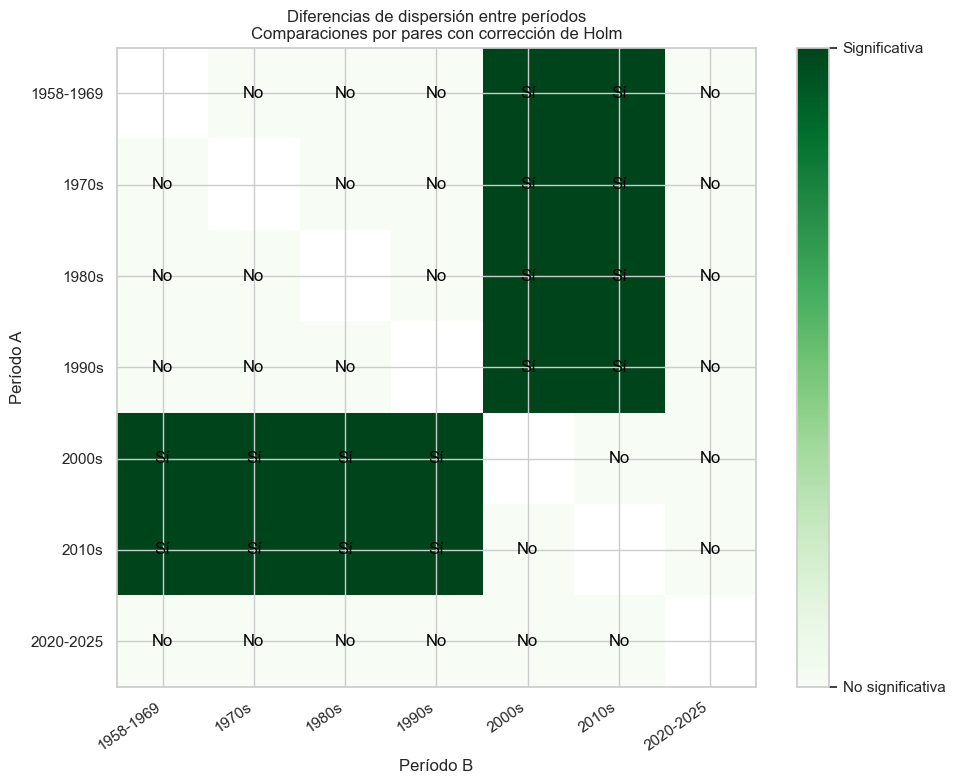

In [167]:

import matplotlib.pyplot as plt
import numpy as np

# Matriz: 1 = diferencia significativa; 0 = no significativa
n_periods = len(period_labels)

significance_matrix = np.full(
    (n_periods, n_periods),
    np.nan
)

for _, row in pairwise_results.iterrows():
    i = period_labels.index(row["Epoch_A"])
    j = period_labels.index(row["Epoch_B"])

    value = int(row["Significant_Holm"])

    significance_matrix[i, j] = value
    significance_matrix[j, i] = value

fig, ax = plt.subplots(figsize=(10, 8))

image = ax.imshow(
    significance_matrix,
    cmap="Greens",
    vmin=0,
    vmax=1
)

ax.set_xticks(range(n_periods))
ax.set_yticks(range(n_periods))
ax.set_xticklabels(period_labels, rotation=35, ha="right")
ax.set_yticklabels(period_labels)

for i in range(n_periods):
    for j in range(n_periods):
        value = significance_matrix[i, j]

        if np.isnan(value):
            continue

        label = "Sí" if value == 1 else "No"

        ax.text(
            j, i, label,
            ha="center",
            va="center",
            color="black"
        )

ax.set_title(
    "Diferencias de dispersión entre períodos\n"
    "Comparaciones por pares con corrección de Holm"
)
ax.set_xlabel("Período B")
ax.set_ylabel("Período A")

colorbar = fig.colorbar(image, ax=ax, ticks=[0, 1])
colorbar.ax.set_yticklabels(["No significativa", "Significativa"])

plt.tight_layout()
plt.show()


In [173]:
significance_matrix

array([[nan,  0.,  0.,  0.,  1.,  1.,  0.],
       [ 0., nan,  0.,  0.,  1.,  1.,  0.],
       [ 0.,  0., nan,  0.,  1.,  1.,  0.],
       [ 0.,  0.,  0., nan,  1.,  1.,  0.],
       [ 1.,  1.,  1.,  1., nan,  0.,  0.],
       [ 1.,  1.,  1.,  1.,  0., nan,  0.],
       [ 0.,  0.,  0.,  0.,  0.,  0., nan]])

In [157]:
## Celda 48 — Gráfico de diferencias de dispersión

def pairwise_permdisp(X_pair, labels_pair, group_order):
    """
    PERMDISP basado en centroides para dos grupos.
    group_order conserva el orden A y B de la comparación.
    """
    groups = np.asarray(group_order)

    def calculate_distances(X, labels):
        distances = np.zeros(len(X), dtype=float)

        for group in groups:
            mask = labels == group
            centroid = X[mask].mean(axis=0)
            distances[mask] = np.linalg.norm(
                X[mask] - centroid, axis=1
            )

        return distances

    def calculate_f(X, labels):
        distances = calculate_distances(X, labels)
        group_distances = [
            distances[labels == group] for group in groups
        ]
        return float(f_oneway(*group_distances).statistic), distances

    observed_f, observed_distances = calculate_f(X_pair, labels_pair)

    rng = np.random.default_rng(RANDOM_SEED_PAIRWISE)
    permuted_statistics = np.empty(N_PERMUTATIONS_PAIRWISE)

    for i in range(N_PERMUTATIONS_PAIRWISE):
        permuted_labels = rng.permutation(labels_pair)
        permuted_f, _ = calculate_f(X_pair, permuted_labels)
        permuted_statistics[i] = permuted_f

    p_value = (
        1 + np.sum(permuted_statistics >= observed_f)
    ) / (N_PERMUTATIONS_PAIRWISE + 1)

    mean_a = observed_distances[labels_pair == groups[0]].mean()
    mean_b = observed_distances[labels_pair == groups[1]].mean()

    grand_mean = observed_distances.mean()
    ss_total = np.sum((observed_distances - grand_mean) ** 2)

    ss_between = sum(
        np.sum(labels_pair == group)
        * (
            observed_distances[labels_pair == group].mean()
            - grand_mean
        ) ** 2
        for group in groups
    )

    eta_squared = ss_between / ss_total if ss_total > 0 else np.nan

    return {
        "F_Statistic": observed_f,
        "P_Value": p_value,
        "Mean_Distance_A": mean_a,
        "Mean_Distance_B": mean_b,
        "Mean_Difference_B_minus_A": mean_b - mean_a,
        "Eta_Squared": eta_squared,
    }


In [158]:
result = pairwise_permdisp(
    X_pair,
    labels_pair,
    group_order=(epoch_a, epoch_b)
)

In [165]:
result

{'F_Statistic': 4.7604405841305555,
 'P_Value': 0.0545,
 'Mean_Distance_A': 1.8678345636320883,
 'Mean_Distance_B': 2.08532408233772,
 'Mean_Difference_B_minus_A': 0.21748951870563182,
 'Eta_Squared': 0.023712044914225194}

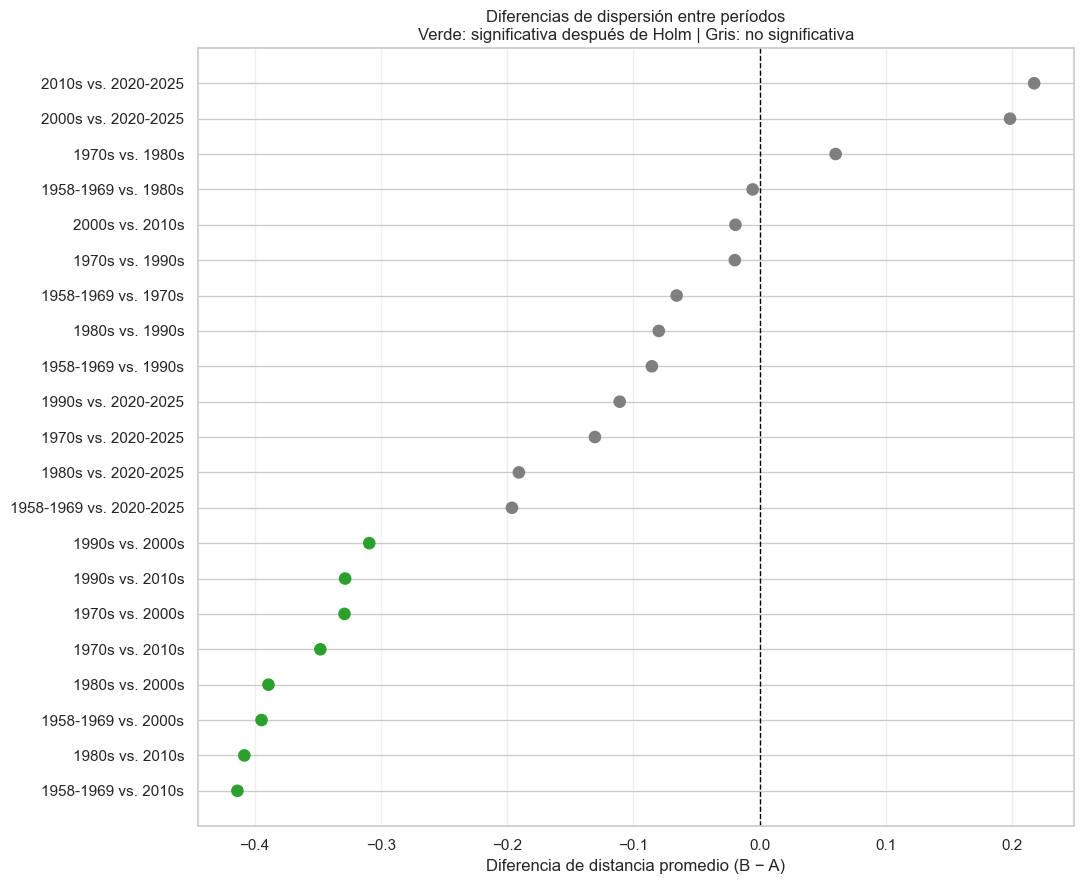

In [159]:

plot_data = pairwise_results.sort_values(
    "Mean_Difference_B_minus_A"
).reset_index(drop=True)

fig, ax = plt.subplots(figsize=(11, 9))

colors = np.where(
    plot_data["Significant_Holm"],
    "tab:green",
    "tab:gray"
)

y_positions = np.arange(len(plot_data))

ax.scatter(
    plot_data["Mean_Difference_B_minus_A"],
    y_positions,
    c=colors,
    s=65,
    zorder=3
)

ax.axvline(0, linestyle="--", linewidth=1, color="black")

labels = (
    plot_data["Epoch_A"] + " vs. " + plot_data["Epoch_B"]
)

ax.set_yticks(y_positions)
ax.set_yticklabels(labels)

ax.set_xlabel("Diferencia de distancia promedio (B − A)")
ax.set_title(
    "Diferencias de dispersión entre períodos\n"
    "Verde: significativa después de Holm | Gris: no significativa"
)

ax.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()


In [180]:
!jupyter nbconvert --to python Untitled1.ipynb

[NbConvertApp] Converting notebook Untitled1.ipynb to python
[NbConvertApp] Writing 78454 bytes to Untitled1.py
